In [1]:
import os, time, json, warnings, random
import numpy as np
import pandas as pd
warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED); np.random.seed(SEED)

working_directory = os.getcwd()          # change if needed
DATA_DIR = os.path.join(working_directory, "Dataset")
OUT_DIR  = os.path.join(working_directory, "outputs")
os.makedirs(OUT_DIR, exist_ok=True)

PATHS = {
    "paintcontrol": os.path.join(DATA_DIR, "paintcontrol-additional-features.csv"),
    "iofrol":       os.path.join(DATA_DIR, "iofrol.csv"),
    "westermo":     os.path.join(DATA_DIR, "westermo.csv"),   # Enhanced Westermo (Zenodo)
}
for k, p in PATHS.items():
    print(k, os.path.exists(p), p)

paintcontrol True /Users/anis/My Research/Software Testing/ML Test Prio/Dataset/paintcontrol-additional-features.csv
iofrol True /Users/anis/My Research/Software Testing/ML Test Prio/Dataset/iofrol.csv
westermo False /Users/anis/My Research/Software Testing/ML Test Prio/Dataset/westermo.csv


In [2]:
def _norm_cols(df):
    df.columns = [c.strip() for c in df.columns]
    return df

def _pick(df, options):
    low = {c.lower(): c for c in df.columns}
    for o in options:
        if o.lower() in low:
            return low[o.lower()]
    return None

def load_project(name, path):
    df = pd.read_csv(path, sep=None, engine="python")
    df = _norm_cols(df)
    col = {
        "test_id":  _pick(df, ["Id", "TestId", "test_id"]),
        "name":     _pick(df, ["Name", "TestName"]),
        "duration": _pick(df, ["Duration", "Time"]),
        "verdict":  _pick(df, ["Verdict", "Result", "Status"]),
        "cycle":    _pick(df, ["Cycle", "BuildId", "Build"]),
        "last_run": _pick(df, ["LastRun", "Last_Run"]),
    }
    missing = [k for k, v in col.items() if v is None and k in ("test_id", "verdict", "cycle")]
    if missing:
        raise ValueError(f"{name}: missing columns {missing}; found {list(df.columns)}")

    out = pd.DataFrame({
        "project":  name,
        "test_id":  df[col["test_id"]].astype(str) if col["test_id"] else df[col["name"]].astype(str),
        "cycle":    pd.to_numeric(df[col["cycle"]], errors="coerce"),
        "duration": pd.to_numeric(df[col["duration"]], errors="coerce") if col["duration"] else np.nan,
        "verdict":  pd.to_numeric(df[col["verdict"]], errors="coerce"),
        "last_run": df[col["last_run"]] if col["last_run"] else pd.NaT,
    })
    out = out.dropna(subset=["cycle", "verdict"])
    out["verdict"] = (out["verdict"] > 0).astype(int)
    out["cycle"] = out["cycle"].astype(int)
    out["row_order"] = np.arange(len(out))
    return out.sort_values(["cycle", "row_order"]).reset_index(drop=True), df

data, raw = {}, {}
for name, p in PATHS.items():
    if os.path.exists(p):
        data[name], raw[name] = load_project(name, p)

def audit(d):
    g = d.groupby("cycle")
    return {
        "rows": len(d),
        "tests": d.test_id.nunique(),
        "cycles": d.cycle.nunique(),
        "fail_rate_%": round(100 * d.verdict.mean(), 2),
        "cycles_with_fail_%": round(100 * (g.verdict.sum() > 0).mean(), 1),
        "dup_test_in_cycle_%": round(100 * d.duplicated(["cycle", "test_id"]).mean(), 2),
    }

print(pd.DataFrame({k: audit(v) for k, v in data.items()}).T)
for k, v in raw.items():
    print(k, list(v.columns))

                 rows    tests  cycles  fail_rate_%  cycles_with_fail_%  \
paintcontrol  25594.0  25594.0   352.0        19.36                73.0   
iofrol        32260.0  32260.0   320.0        28.79                84.7   

              dup_test_in_cycle_%  
paintcontrol                  0.0  
iofrol                        0.0  
paintcontrol ['Id', 'Name', 'Duration', 'CalcPrio', 'LastRun', 'LastResults', 'Verdict', 'Cycle', 'DurationGroup', 'TimeGroup']
iofrol ['Id', 'Name', 'Duration', 'LastRun', 'LastResults', 'Verdict', 'Cycle']


In [4]:
print(df.shape)
print(list(df.columns))
print(df.head(5).T)
print(df.dtypes)

(25594, 10)
['Id', 'Name', 'Duration', 'CalcPrio', 'LastRun', 'LastResults', 'Verdict', 'Cycle', 'DurationGroup', 'TimeGroup']
                                 0                    1                    2  \
Id                               1                    2                    3   
Name                        112180               112180               112175   
Duration                      1000                 1000                39050   
CalcPrio                         0                    0                    0   
LastRun        2016-01-12 09:17:00  2016-01-12 09:39:00  2016-01-12 10:32:00   
LastResults                    [1]               [0, 1]                  [0]   
Verdict                          0                    0                    0   
Cycle                            1                    1                    1   
DurationGroup                    2                    2                    0   
TimeGroup                        2                    2                  

In [5]:
import ast

d = df.copy()
d["Verdict"] = (d["Verdict"] > 0).astype(int)
d["LR"] = d["LastResults"].apply(lambda s: ast.literal_eval(s) if isinstance(s, str) else [])
d["LR_len"] = d["LR"].apply(len)
d = d.sort_values("Id").reset_index(drop=True)

prev_verdict = d.groupby("Name")["Verdict"].shift(1)
mask = prev_verdict.notna()
match = (d.loc[mask, "LR"].apply(lambda l: l[0] if l else np.nan) == prev_verdict[mask]).mean()
print("LastResults[0] == previous verdict of same test:", round(match, 4))
print("LastResults length: min/median/max:", d.LR_len.min(), d.LR_len.median(), d.LR_len.max())

runs = d.groupby(["Cycle", "Name"]).size()
print("cycles:", d.Cycle.nunique(), "| tests:", d.Name.nunique())
print("share of (cycle,test) pairs with >1 run:", round((runs > 1).mean(), 4))
print("runs per cycle: min/median/max:", d.groupby("Cycle").size().agg(["min","median","max"]).tolist())
print("overall fail rate (rows):", round(d.Verdict.mean(), 4))

ct = (d.groupby(["Cycle", "Name"])
        .agg(n_runs=("Verdict", "size"),
             duration=("Duration", "sum"),
             fail=("Verdict", "max"),
             n_fail=("Verdict", "sum"),
             first_time=("LastRun", "min"))
        .reset_index())
print(ct.shape, "| fail rate (cycle-test):", round(ct.fail.mean(), 4))
print("cycles with at least one failure:", round((ct.groupby("Cycle").fail.sum() > 0).mean(), 3))

LastResults[0] == previous verdict of same test: 1.0
LastResults length: min/median/max: 1 160.0 395
cycles: 352 | tests: 89
share of (cycle,test) pairs with >1 run: 0.0903
runs per cycle: min/median/max: [1.0, 76.0, 385.0]
overall fail rate (rows): 0.1936
(22260, 7) | fail rate (cycle-test): 0.1633
cycles with at least one failure: 0.73


In [6]:
d["LastRun"] = pd.to_datetime(d["LastRun"], errors="coerce")
first_idx = d.groupby(["Cycle", "Name"])["Id"].idxmin()
first = d.loc[first_idx, ["Cycle", "Name", "LR"]].set_index(["Cycle", "Name"])

ct = ct.merge(first.reset_index(), on=["Cycle", "Name"], how="left")
ct["first_time"] = pd.to_datetime(ct["first_time"], errors="coerce")
ct = ct.sort_values(["Cycle", "first_time", "Name"]).reset_index(drop=True)

def hist_feats(lr):
    a = np.asarray(lr, dtype=int)
    n = len(a)
    if n == 0:
        return dict(n_prev=0, fr_all=0.0, last1=0, fr3=0.0, fr5=0.0, fr10=0.0, fr20=0.0,
                    ewma=0.0, streak_fail=0, streak_pass=0, since_fail=0, flips20=0, n_fail=0)
    w = 0.8 ** np.arange(min(n, 50)); w /= w.sum()
    ones = np.flatnonzero(a == 1)
    sf = int(ones[0]) if len(ones) else n
    lead = int(np.argmax(a != a[0])) if (a != a[0]).any() else n
    h20 = a[:20]
    return dict(n_prev=n, fr_all=a.mean(), last1=int(a[0]),
                fr3=a[:3].mean(), fr5=a[:5].mean(), fr10=a[:10].mean(), fr20=h20.mean(),
                ewma=float((a[:50] * w).sum()),
                streak_fail=lead if a[0] == 1 else 0, streak_pass=lead if a[0] == 0 else 0,
                since_fail=sf, flips20=int((np.diff(h20) != 0).sum()), n_fail=int(a.sum()))

H = pd.DataFrame([hist_feats(l) for l in ct["LR"]])
ct = pd.concat([ct.reset_index(drop=True), H], axis=1)

ct = ct.sort_values(["Name", "Cycle"]).reset_index(drop=True)
gN = ct.groupby("Name")
ct["prev_dur_mean"] = gN["duration"].transform(lambda s: s.shift(1).expanding().mean())
ct["prev_dur_last"] = gN["duration"].shift(1)
ct["prev_dur_std"]  = gN["duration"].transform(lambda s: s.shift(1).expanding().std())
ct["prev_dur_mean"] = ct["prev_dur_mean"].fillna(ct["prev_dur_mean"].median())
ct["prev_dur_last"] = ct["prev_dur_last"].fillna(ct["prev_dur_mean"])
ct["prev_dur_std"]  = ct["prev_dur_std"].fillna(0.0)
ct["dur_ratio"]     = ct["prev_dur_last"] / (ct["prev_dur_mean"] + 1e-9)

cyc_start = ct.groupby("Cycle")["first_time"].transform("min")
ct["prev_run_time"] = gN["first_time"].shift(1)
ct["gap_hours"] = ((cyc_start - ct["prev_run_time"]).dt.total_seconds() / 3600).clip(lower=0)
ct["gap_hours"] = ct["gap_hours"].fillna(ct["gap_hours"].median())
ct["gap_cycles"] = gN["Cycle"].diff().fillna(0)

ct["age_cycles"] = ct["Cycle"] - gN["Cycle"].transform("min")
ct["n_tests_cycle"] = ct.groupby("Cycle")["Name"].transform("size")
ct["prev_nruns"] = gN["n_runs"].shift(1).fillna(1)

ct = ct.sort_values(["Cycle", "first_time", "Name"]).reset_index(drop=True)
ct = ct.rename(columns={"fail": "y"})

FEATS = ["n_prev","fr_all","last1","fr3","fr5","fr10","fr20","ewma","streak_fail","streak_pass",
         "since_fail","flips20","n_fail","prev_dur_mean","prev_dur_last","prev_dur_std","dur_ratio",
         "gap_hours","gap_cycles","age_cycles","n_tests_cycle","prev_nruns"]
print(ct[FEATS].isna().sum().sum(), "NaNs;", ct.shape)
print(ct[FEATS + ["y"]].corr()["y"].drop("y").sort_values(ascending=False).round(3))

0 NaNs; (22260, 31)
n_fail           0.800
last1            0.576
fr3              0.561
ewma             0.516
fr5              0.493
fr10             0.400
fr20             0.370
streak_fail      0.366
dur_ratio        0.262
prev_nruns       0.240
prev_dur_last    0.164
flips20          0.158
fr_all           0.119
gap_hours        0.046
prev_dur_mean    0.040
gap_cycles       0.028
prev_dur_std     0.010
n_tests_cycle    0.003
n_fail          -0.015
age_cycles      -0.048
n_prev          -0.051
since_fail      -0.251
streak_pass     -0.251
Name: y, dtype: float64


In [8]:
#Cell 7
cols = list(ct.columns)
idx = [i for i, c in enumerate(cols) if c == "n_fail"]
print("positions of n_fail:", idx)

if len(idx) == 2:
    cols[idx[0]] = "n_fail_cycle"
    cols[idx[1]] = "n_fail"
    ct.columns = cols

print("columns unique:", ct.columns.is_unique)
print("has n_fail_cycle:", "n_fail_cycle" in ct.columns)

chk = ct.sort_values(["Name", "Cycle"]).copy()
g = chk.groupby("Name")
chk["next_nprev"] = g["n_prev"].shift(-1)
chk["next_nfail"] = g["n_fail"].shift(-1)
m = chk["next_nprev"].notna()

t1 = ((chk.loc[m, "next_nprev"] - chk.loc[m, "n_prev"]) == chk.loc[m, "n_runs"]).mean()
t2 = ((chk.loc[m, "next_nfail"] - chk.loc[m, "n_fail"]) == chk.loc[m, "n_fail_cycle"]).mean()
t3 = [f for f in FEATS if (ct[f] == ct["y"]).all()]
t4 = [f for f in FEATS if abs(ct[f].corr(ct["y"])) > 0.9]

print("T1:", round(t1, 4))
print("T2:", round(t2, 4))
print("T3 identical to target:", t3)
print("T4 |corr| > 0.9:", t4)
print(ct[FEATS + ["y"]].corr()["y"].drop("y").sort_values(ascending=False).round(3))

positions of n_fail: [5, 20]
columns unique: True
has n_fail_cycle: True
T1: 1.0
T2: 1.0
T3 identical to target: []
T4 |corr| > 0.9: []
last1            0.576
fr3              0.561
ewma             0.516
fr5              0.493
fr10             0.400
fr20             0.370
streak_fail      0.366
dur_ratio        0.262
prev_nruns       0.240
prev_dur_last    0.164
flips20          0.158
fr_all           0.119
gap_hours        0.046
prev_dur_mean    0.040
gap_cycles       0.028
prev_dur_std     0.010
n_tests_cycle    0.003
n_fail          -0.015
age_cycles      -0.048
n_prev          -0.051
since_fail      -0.251
streak_pass     -0.251
Name: y, dtype: float64


In [11]:
#Cell 8: metrics, split, and heuristic baselines
cycles = np.sort(ct["Cycle"].unique())
cut = cycles[int(0.8 * len(cycles)) - 1]
train = ct[ct["Cycle"] <= cut].copy()
test  = ct[ct["Cycle"] >  cut].copy()
print("train cycles:", train.Cycle.nunique(), "| test cycles:", test.Cycle.nunique(),
      "| test cycles with failures:", int((test.groupby("Cycle").y.sum() > 0).sum()))

def apfd_one(y_ord):
    n, m = len(y_ord), int(y_ord.sum())
    if m == 0 or n == 0:
        return np.nan
    pos = np.flatnonzero(y_ord) + 1
    return 1 - pos.sum() / (n * m) + 1 / (2 * n)

def tcse_one(y_ord, dur_ord, frac):
    m = y_ord.sum()
    if m == 0:
        return np.nan
    cum = np.cumsum(dur_ord)
    k = np.searchsorted(cum, frac * cum[-1], side="right")
    return y_ord[:k].sum() / m

def evaluate(frame, score, seed=0, budgets=(0.3, 0.5, 0.7)):
    rng = np.random.default_rng(seed)
    res = {"APFD": [], **{f"TCSE{int(b*100)}": [] for b in budgets}}
    for _, g in frame.groupby("Cycle", sort=True):
        s = score.loc[g.index].to_numpy()
        tie = rng.random(len(g))
        order = np.lexsort((tie, -s))
        y = g["y"].to_numpy()[order]
        dur = g["duration"].to_numpy()[order].astype(float)
        res["APFD"].append(apfd_one(y))
        for b in budgets:
            res[f"TCSE{int(b*100)}"].append(tcse_one(y, dur, b))
    return {k: float(np.nanmean(v)) for k, v in res.items()}

rows = {}
rnd = [evaluate(test, pd.Series(np.zeros(len(test)), index=test.index), seed=s) for s in range(30)]
rows["random (30 seeds)"] = {k: np.mean([r[k] for r in rnd]) for k in rnd[0]}
rows["log order"] = evaluate(test, -test["first_time"].rank(method="first"))
for name, col in [("last result", "last1"), ("fail rate (all)", "fr_all"),
                  ("fail rate (last 5)", "fr5"), ("EWMA", "ewma")]:
    rows[name] = evaluate(test, test[col])
rows["short duration first"] = evaluate(test, -test["prev_dur_last"])
res_df = pd.DataFrame(rows).T.round(4)
print(res_df)


train cycles: 281 | test cycles: 71 | test cycles with failures: 57
                        APFD  TCSE30  TCSE50  TCSE70
random (30 seeds)     0.4996  0.2491  0.4472  0.6352
log order             0.5705  0.3761  0.5182  0.6420
last result           0.7814  0.6641  0.7728  0.8136
fail rate (all)       0.8425  0.7741  0.8656  0.8792
fail rate (last 5)    0.8493  0.7629  0.8384  0.8627
EWMA                  0.8834  0.8136  0.8831  0.9065
short duration first  0.2847  0.2689  0.4062  0.4688


In [12]:
#Cell 9: first honest model results
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

Xtr, ytr, Xte = train[FEATS], train["y"], test[FEATS]
models = {
    "LogReg": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced")),
    "RF": RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight="balanced_subsample",
                                 n_jobs=-1, random_state=SEED),
    "HistGB": HistGradientBoostingClassifier(max_depth=4, learning_rate=0.05, max_iter=300, random_state=SEED),
}
out = {}
for name, mdl in models.items():
    mdl.fit(Xtr, ytr)
    p = pd.Series(mdl.predict_proba(Xte)[:, 1], index=test.index)
    out[name] = evaluate(test, p)
    out[name]["AUC"] = roc_auc_score(test["y"], p)
print(pd.concat([res_df, pd.DataFrame(out).T.round(4)]))

                        APFD  TCSE30  TCSE50  TCSE70     AUC
random (30 seeds)     0.4996  0.2491  0.4472  0.6352     NaN
log order             0.5705  0.3761  0.5182  0.6420     NaN
last result           0.7814  0.6641  0.7728  0.8136     NaN
fail rate (all)       0.8425  0.7741  0.8656  0.8792     NaN
fail rate (last 5)    0.8493  0.7629  0.8384  0.8627     NaN
EWMA                  0.8834  0.8136  0.8831  0.9065     NaN
short duration first  0.2847  0.2689  0.4062  0.4688     NaN
LogReg                0.7971  0.7093  0.7744  0.8119  0.7952
RF                    0.7673  0.6436  0.7005  0.7712  0.7260
HistGB                0.8106  0.6837  0.7779  0.8583  0.7927


In [13]:
#Cell 10: stationary features, validation-based selection, blending
def ewma_a(lr, a, k=100):
    x = np.asarray(lr[:k], dtype=float)
    if len(x) == 0: return 0.0
    w = a * (1 - a) ** np.arange(len(x)); w /= w.sum()
    return float((x * w).sum())

for a in (0.1, 0.3, 0.5):
    ct[f"ewma_{a}"] = [ewma_a(l, a) for l in ct["LR"]]

train = ct[ct["Cycle"] <= cut].copy()
test  = ct[ct["Cycle"] >  cut].copy()

tr_cycles = np.sort(train["Cycle"].unique())
vcut = tr_cycles[int(0.8 * len(tr_cycles)) - 1]
fit_df = train[train["Cycle"] <= vcut]
val_df = train[train["Cycle"] >  vcut]

EW = ["ewma", "ewma_0.1", "ewma_0.3", "ewma_0.5"]
SETS = {
    "all": FEATS + EW[1:],
    "stationary": ["last1","fr3","fr5","fr10","fr20","fr_all","streak_fail","streak_pass",
                   "since_fail","flips20","dur_ratio","prev_nruns"] + EW,
    "history_core": ["last1","fr3","fr5","fr_all"] + EW,
}

def make(name):
    if name == "LogReg":
        return make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced"))
    return HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=200,
                                          l2_regularization=1.0, random_state=SEED)

def blend(frame, p, w=0.5):
    r1 = p.groupby(frame["Cycle"]).rank(pct=True)
    r2 = frame["ewma"].groupby(frame["Cycle"]).rank(pct=True)
    return w * r1 + (1 - w) * r2

rows = []
for fs, cols in SETS.items():
    for mn in ("LogReg", "HistGB"):
        m = make(mn).fit(fit_df[cols], fit_df["y"])
        pv = pd.Series(m.predict_proba(val_df[cols])[:, 1], index=val_df.index)
        v = evaluate(val_df, pv)["APFD"]
        vb = evaluate(val_df, blend(val_df, pv))["APFD"]
        m2 = make(mn).fit(train[cols], train["y"])
        pt = pd.Series(m2.predict_proba(test[cols])[:, 1], index=test.index)
        rows.append(dict(features=fs, model=mn, val_APFD=v, val_blend=vb,
                         test_APFD=evaluate(test, pt)["APFD"],
                         test_blend=evaluate(test, blend(test, pt))["APFD"]))
print("EWMA val:", round(evaluate(val_df, val_df["ewma"])["APFD"], 4),
      "| EWMA test:", round(evaluate(test, test["ewma"])["APFD"], 4))
print(pd.DataFrame(rows).round(4))


EWMA val: 0.7543 | EWMA test: 0.8834
       features   model  val_APFD  val_blend  test_APFD  test_blend
0           all  LogReg    0.7455     0.7591     0.7969      0.8533
1           all  HistGB    0.7197     0.7445     0.7323      0.8424
2    stationary  LogReg    0.7468     0.7552     0.8135      0.8608
3    stationary  HistGB    0.7492     0.7589     0.7981      0.8601
4  history_core  LogReg    0.7309     0.7420     0.7735      0.8410
5  history_core  HistGB    0.7564     0.7634     0.7789      0.8578


In [14]:
#Cell 11: rolling-origin evaluation with paired tests
from scipy.stats import wilcoxon

def apfd_by_cycle(frame, score, seed=0):
    rng = np.random.default_rng(seed)
    out = {}
    for c, g in frame.groupby("Cycle", sort=True):
        s = score.loc[g.index].to_numpy()
        order = np.lexsort((rng.random(len(g)), -s))
        out[c] = apfd_one(g["y"].to_numpy()[order])
    return pd.Series(out)

cyc = np.sort(ct["Cycle"].unique())
bounds = [cyc[int(len(cyc) * q) - 1] for q in (0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0)]
cols_st = SETS["stationary"]

per_cycle = {k: [] for k in ["random", "ewma", "fr_all", "LogReg", "HistGB", "blend_LogReg", "blend_HistGB"]}
fold_id = []
for k in range(len(bounds) - 1):
    tr = ct[ct["Cycle"] <= bounds[k]]
    te = ct[(ct["Cycle"] > bounds[k]) & (ct["Cycle"] <= bounds[k + 1])]
    per_cycle["random"].append(apfd_by_cycle(te, pd.Series(0.0, index=te.index)))
    per_cycle["ewma"].append(apfd_by_cycle(te, te["ewma"]))
    per_cycle["fr_all"].append(apfd_by_cycle(te, te["fr_all"]))
    for mn in ("LogReg", "HistGB"):
        m = make(mn).fit(tr[cols_st], tr["y"])
        p = pd.Series(m.predict_proba(te[cols_st])[:, 1], index=te.index)
        per_cycle[mn].append(apfd_by_cycle(te, p))
        per_cycle[f"blend_{mn}"].append(apfd_by_cycle(te, blend(te, p)))
    fold_id.append(k)

P = {k: pd.concat(v) for k, v in per_cycle.items()}
fold_of = pd.concat([pd.Series(k, index=per_cycle["ewma"][k].index) for k in fold_id])
tab = pd.DataFrame(P)
tab["fold"] = fold_of
print("Mean APFD by fold:\n", tab.groupby("fold").mean().round(4))
print("\nOverall mean (cycles with failures):\n", tab.drop(columns="fold").mean().round(4))

base = tab["ewma"]
rows = []
for k in ["fr_all", "LogReg", "HistGB", "blend_LogReg", "blend_HistGB"]:
    x = pd.concat([tab[k], base], axis=1).dropna()
    diff = x.iloc[:, 0] - x.iloc[:, 1]
    p = wilcoxon(diff).pvalue if (diff != 0).any() else np.nan
    rows.append(dict(method=k, n=len(x), mean_diff_vs_EWMA=diff.mean(),
                     win_rate=(diff > 0).mean() + 0.5 * (diff == 0).mean(), p_wilcoxon=p))
print("\nPaired vs EWMA:\n", pd.DataFrame(rows).round(4))

Mean APFD by fold:
       random    ewma  fr_all  LogReg  HistGB  blend_LogReg  blend_HistGB
fold                                                                    
0     0.4621  0.7977  0.7397  0.3916  0.7126        0.6281        0.7833
1     0.4558  0.8488  0.7485  0.7603  0.7659        0.8266        0.8206
2     0.4574  0.6425  0.5883  0.6274  0.6271        0.6459        0.6419
3     0.5619  0.8375  0.7458  0.8232  0.8067        0.8281        0.8309
4     0.4482  0.9640  0.9004  0.8557  0.8391        0.9215        0.9263
5     0.4737  0.8135  0.7905  0.7663  0.7637        0.7892        0.7836

Overall mean (cycles with failures):
 random          0.4785
ewma            0.8117
fr_all          0.7460
LogReg          0.6986
HistGB          0.7494
blend_LogReg    0.7676
blend_HistGB    0.7932
dtype: float64

Paired vs EWMA:
          method    n  mean_diff_vs_EWMA  win_rate  p_wilcoxon
0        fr_all  190            -0.0657    0.2658      0.0000
1        LogReg  190            -0.1131

In [16]:
%pip install lightgbm

  Using cached lightgbm-4.7.0-py3-none-macosx_12_0_arm64.whl.metadata (18 kB)
  Using cached narwhals-2.26.0-py3-none-any.whl.metadata (15 kB)
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.8/114.8 kB 413.2 kB/s eta 0:00:001m305.1 kB/s eta 0:00:01
Using cached lightgbm-4.7.0-py3-none-macosx_12_0_arm64.whl (1.5 MB)
Using cached narwhals-2.26.0-py3-none-any.whl (474 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.0/14.0 MB 4.2 MB/s eta 0:00:000:00:01m eta 0:00:01
  Attempting uninstall: numpy
    Found existing installation: numpy 2.4.6
    Uninstalling numpy-2.4.6:
      Successfully uninstalled numpy-2.4.6
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gensim 4.3.0 requires FuzzyTM>=0.4.0, which is not installed.
streamlit 1.30.0 requires protobuf<5,>=3.20, but you have protobuf 7.34.0 which is incompatible.
shap 0.51.0 requires numpy>=2, but you have numpy

In [17]:
#Cell 12: tuned EWMA and a LambdaRank model
try:
    import lightgbm as lgb
except ImportError:
    raise SystemExit("Run once in a cell:  !pip install lightgbm   then rerun this cell")

ALPHAS = [0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7]
for a in ALPHAS:
    if f"ew_{a}" not in ct:
        ct[f"ew_{a}"] = [ewma_a(l, a) for l in ct["LR"]]

def mean_apfd(frame, scorecol):
    return apfd_by_cycle(frame, frame[scorecol]).mean()

def fit_ranker(tr, cols):
    tr = tr.sort_values(["Cycle", "first_time", "Name"])
    grp = tr.groupby("Cycle", sort=True).size().to_numpy()
    m = lgb.LGBMRanker(objective="lambdarank", n_estimators=200, learning_rate=0.05,
                       num_leaves=8, min_child_samples=30, subsample=0.8, colsample_bytree=0.8,
                       random_state=SEED, verbose=-1)
    m.fit(tr[cols], tr["y"], group=grp)
    return m

cols_rank = SETS["stationary"] + [f"ew_{a}" for a in ALPHAS]
res12 = {k: [] for k in ["ewma_fixed", "ewma_tuned", "ewma_tuned_tb", "lgbm_rank", "blend_rank"]}
chosen = []
for k in range(len(bounds) - 1):
    tr = ct[ct["Cycle"] <= bounds[k]]
    te = ct[(ct["Cycle"] > bounds[k]) & (ct["Cycle"] <= bounds[k + 1])].copy()
    sc = {a: mean_apfd(tr, f"ew_{a}") for a in ALPHAS}
    best = max(sc, key=sc.get); chosen.append(best)
    te["s_tuned"] = te[f"ew_{best}"]
    te["s_tb"] = te[f"ew_{best}"] + 1e-3 * te["fr20"] + 1e-5 * te["fr_all"]
    res12["ewma_fixed"].append(apfd_by_cycle(te, te["ewma"]))
    res12["ewma_tuned"].append(apfd_by_cycle(te, te["s_tuned"]))
    res12["ewma_tuned_tb"].append(apfd_by_cycle(te, te["s_tb"]))
    rk = fit_ranker(tr, cols_rank)
    p = pd.Series(rk.predict(te[cols_rank]), index=te.index)
    res12["lgbm_rank"].append(apfd_by_cycle(te, p))
    r1 = p.groupby(te["Cycle"]).rank(pct=True); r2 = te["s_tb"].groupby(te["Cycle"]).rank(pct=True)
    res12["blend_rank"].append(apfd_by_cycle(te, 0.5 * r1 + 0.5 * r2))

T = pd.DataFrame({k: pd.concat(v) for k, v in res12.items()})
print("chosen alpha per fold:", chosen)
print(T.mean().round(4))
base = T["ewma_fixed"]
for k in T.columns[1:]:
    diff = (T[k] - base).dropna()
    print(k, "diff", round(diff.mean(), 4), "win", round((diff > 0).mean(), 3),
          "p", round(wilcoxon(diff).pvalue, 4) if (diff != 0).any() else None)

chosen alpha per fold: [0.1, 0.5, 0.2, 0.2, 0.2, 0.2]
ewma_fixed       0.8117
ewma_tuned       0.8079
ewma_tuned_tb    0.8097
lgbm_rank        0.8040
blend_rank       0.8114
dtype: float64
ewma_tuned diff -0.0039 win 0.095 p 0.2852
ewma_tuned_tb diff -0.002 win 0.1 p 0.5324
lgbm_rank diff -0.0077 win 0.195 p 0.0508
blend_rank diff -0.0003 win 0.211 p 0.3334


In [19]:
#Cell 13: one reusable pipeline for any project
import glob, ast

def build_ct(df):
    d = df.copy()
    d["Verdict"] = (pd.to_numeric(d["Verdict"], errors="coerce").fillna(0) > 0).astype(int)
    d["Cycle"] = pd.to_numeric(d["Cycle"], errors="coerce")
    d = d.dropna(subset=["Cycle"]).copy()
    d["Cycle"] = d["Cycle"].astype(int)
    if "Id" not in d: d["Id"] = np.arange(len(d))
    d = d.sort_values("Id").reset_index(drop=True)
    d["LastRun"] = pd.to_datetime(d.get("LastRun"), errors="coerce")
    key = d.groupby(["Cycle", "Name"])
    ct = key.agg(n_runs=("Verdict", "size"), duration=("Duration", "sum"),
                 y=("Verdict", "max"), n_fail_cycle=("Verdict", "sum"),
                 first_time=("LastRun", "min"), first_id=("Id", "min")).reset_index()
    if "LastResults" in d.columns:
        lr_map = d.set_index("Id")["LastResults"]
        ct["LR"] = [ast.literal_eval(s) if isinstance(s, str) else list(s) for s in lr_map.loc[ct["first_id"]]]
    else:
        ct = ct.sort_values(["Name", "Cycle"]).reset_index(drop=True)
        lrs = []
        for _, g in ct.groupby("Name", sort=False):
            ys = g["y"].to_numpy()
            lrs += [list(ys[:k][::-1]) for k in range(len(ys))]
        ct["LR"] = lrs
    ct = ct.sort_values(["Cycle", "first_time", "Name"]).reset_index(drop=True)
    H = pd.DataFrame([hist_feats(l) for l in ct["LR"]])
    ct = pd.concat([ct, H], axis=1)
    for a in ALPHAS:
        ct[f"ew_{a}"] = [ewma_a(l, a) for l in ct["LR"]]
    ct["ewma"] = [ewma_a(l, 0.2) for l in ct["LR"]]
    ct = ct.sort_values(["Name", "Cycle"]).reset_index(drop=True)
    gN = ct.groupby("Name")
    ct["prev_dur_mean"] = gN["duration"].transform(lambda s: s.shift(1).expanding().mean())
    ct["prev_dur_last"] = gN["duration"].shift(1)
    ct["prev_dur_mean"] = ct["prev_dur_mean"].fillna(ct["prev_dur_mean"].median())
    ct["prev_dur_last"] = ct["prev_dur_last"].fillna(ct["prev_dur_mean"])
    ct["dur_ratio"] = ct["prev_dur_last"] / (ct["prev_dur_mean"] + 1e-9)
    ct["prev_nruns"] = gN["n_runs"].shift(1).fillna(1)
    ct = ct.sort_values(["Cycle", "first_time", "Name"]).reset_index(drop=True)
    # leakage tests
    c2 = ct.sort_values(["Name", "Cycle"]); g2 = c2.groupby("Name")
    nx = g2["n_prev"].shift(-1); m = nx.notna()
    if "LastResults" in d.columns:
        t1 = ((nx[m] - c2.loc[m, "n_prev"]) == c2.loc[m, "n_runs"]).mean()
    else:
        t1 = np.nan
    return ct, t1

STAT = SETS["stationary"] + [f"ew_{a}" for a in ALPHAS]
STAT = list(dict.fromkeys(STAT))

def rolling_eval(ct, name):
    cyc = np.sort(ct["Cycle"].unique())
    if len(cyc) < 30:
        return None
    bnd = [cyc[int(len(cyc) * q) - 1] for q in (0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0)]
    out = {k: [] for k in ["random", "ewma", "HistGB", "lgbm_rank", "blend_rank"]}
    for k in range(len(bnd) - 1):
        tr = ct[ct["Cycle"] <= bnd[k]]
        te = ct[(ct["Cycle"] > bnd[k]) & (ct["Cycle"] <= bnd[k + 1])]
        out["random"].append(apfd_by_cycle(te, pd.Series(0.0, index=te.index)))
        out["ewma"].append(apfd_by_cycle(te, te["ewma"]))
        hg = make("HistGB").fit(tr[STAT], tr["y"])
        out["HistGB"].append(apfd_by_cycle(te, pd.Series(hg.predict_proba(te[STAT])[:, 1], index=te.index)))
        rk = fit_ranker(tr, STAT)
        p = pd.Series(rk.predict(te[STAT]), index=te.index)
        out["lgbm_rank"].append(apfd_by_cycle(te, p))
        r1 = p.groupby(te["Cycle"]).rank(pct=True); r2 = te["ewma"].groupby(te["Cycle"]).rank(pct=True)
        out["blend_rank"].append(apfd_by_cycle(te, 0.5 * r1 + 0.5 * r2))
    T = pd.DataFrame({k: pd.concat(v) for k, v in out.items()})
    T["project"] = name
    return T

print([os.path.relpath(p, DATA_DIR) for p in glob.glob(os.path.join(DATA_DIR, "**", "*.*"), recursive=True)])

['NSGAII_Best_Solution-final_org.txt', 'paintcontrol-additional-features.csv', 'paintcontrol-final-priority3.csv', 'paintcontrol-final_Tom.csv', 'paintcontrol-final1.csv', 'NSGAII_Best_Solution-final_org_50genes1.csv', 'paintcontrol-final copy.csv', 'paintcontrol-final.csv', 'NSGAII_Best_Solution-final_org.csv', 'cl3_NSGAII_50genes1.csv', 'iofrol.csv', 'paintcontrol-additional-features copy.csv', 'paintcontrol_org.csv', 'NSGAII_Best_Solution-final_org_50genes.txt', 'rtp-torrent/readme.md', 'rtp-torrent/tr_all_built_commits.csv', 'rtp-torrent/eclipse@jetty.project', 'rtp-torrent/neuland@jade4j/neuland@jade4j-pr.csv', 'rtp-torrent/neuland@jade4j/neuland@jade4j.csv', 'rtp-torrent/neuland@jade4j/neuland@jade4j-offenders.csv', 'rtp-torrent/neuland@jade4j/neuland@jade4j-patches.csv', 'rtp-torrent/neuland@jade4j/baseline/jade4j@random.csv', 'rtp-torrent/neuland@jade4j/baseline/jade4j@optimal-failure.csv', 'rtp-torrent/neuland@jade4j/baseline/jade4j@recently-failed.csv', 'rtp-torrent/neuland@j

In [21]:
#cell 14 check 
STAT = ["last1", "fr3", "fr5", "fr10", "fr20", "fr_all", "streak_fail", "streak_pass",
        "since_fail", "flips20", "dur_ratio", "prev_nruns", "ewma"] + [f"ew_{a}" for a in ALPHAS]
print(STAT)

['last1', 'fr3', 'fr5', 'fr10', 'fr20', 'fr_all', 'streak_fail', 'streak_pass', 'since_fail', 'flips20', 'dur_ratio', 'prev_nruns', 'ewma', 'ew_0.05', 'ew_0.1', 'ew_0.2', 'ew_0.3', 'ew_0.4', 'ew_0.5', 'ew_0.6', 'ew_0.7']


In [24]:
WDIR = os.path.join(DATA_DIR, "westermo")
wfiles = sorted(glob.glob(os.path.join(WDIR, "converted_system*_result.csv")))
for p in wfiles:
    x = pd.read_csv(p, sep=None, engine="python", nrows=3)
    n = sum(1 for _ in open(p, "rb")) - 1
    print(os.path.basename(p), "| rows:", n, "|", round(os.path.getsize(p) / 1e6, 1), "MB |", list(x.columns))
print(x.head(3).T)

converted_system11_result.csv | rows: 41976 | 45.7 MB | ['Id', 'Name', 'Duration', 'CalcPrio', 'LastRun', 'LastResults', 'Verdict', 'Cycle']
converted_system13_result.csv | rows: 81858 | 109.7 MB | ['Id', 'Name', 'Duration', 'CalcPrio', 'LastRun', 'LastResults', 'Verdict', 'Cycle']
converted_system21_result.csv | rows: 65796 | 143.1 MB | ['Id', 'Name', 'Duration', 'CalcPrio', 'LastRun', 'LastResults', 'Verdict', 'Cycle']
converted_system28_result.csv | rows: 68905 | 51.0 MB | ['Id', 'Name', 'Duration', 'CalcPrio', 'LastRun', 'LastResults', 'Verdict', 'Cycle']
converted_system30_result.csv | rows: 184815 | 645.5 MB | ['Id', 'Name', 'Duration', 'CalcPrio', 'LastRun', 'LastResults', 'Verdict', 'Cycle']
converted_system33_result.csv | rows: 167260 | 604.7 MB | ['Id', 'Name', 'Duration', 'CalcPrio', 'LastRun', 'LastResults', 'Verdict', 'Cycle']
converted_system46_result.csv | rows: 187431 | 652.7 MB | ['Id', 'Name', 'Duration', 'CalcPrio', 'LastRun', 'LastResults', 'Verdict', 'Cycle']
conve

In [25]:
#Cell 15: run the three projects
def make_base(path):
    df = pd.read_csv(path, usecols=["Id", "Name", "Duration", "LastRun", "Verdict", "Cycle"])
    df["y"] = (pd.to_numeric(df["Verdict"], errors="coerce").fillna(0) > 0).astype(int)
    df["LastRun"] = pd.to_datetime(df["LastRun"], errors="coerce")
    df = df.dropna(subset=["Cycle"])
    df["Cycle"] = df["Cycle"].astype(int)
    base = (df.groupby(["Cycle", "Name"], sort=False)
              .agg(n_runs=("y", "size"), duration=("Duration", "sum"), y=("y", "max"),
                   n_fail_cycle=("y", "sum"), first_time=("LastRun", "min"), first_id=("Id", "min"))
              .reset_index())
    return base

def make_feats(base):
    b = base.sort_values(["Name", "Cycle"]).reset_index(drop=True)
    parts = []
    for _, g in b.groupby("Name", sort=False):
        y = g["y"].to_numpy(float); nr = g["n_runs"].to_numpy(float)
        nf = g["n_fail_cycle"].to_numpy(float); dur = g["duration"].to_numpy(float)
        n = len(y)
        s = np.r_[np.nan, y[:-1]]
        sv = pd.Series(s)
        f = {"last1": np.nan_to_num(s)}
        for k in (3, 5, 10, 20):
            f[f"fr{k}"] = sv.rolling(k, min_periods=1).mean().fillna(0).to_numpy()
        for a in ALPHAS:
            f[f"ew_{a}"] = sv.ewm(alpha=a).mean().fillna(0).to_numpy()
        f["ewma"] = f["ew_0.2"]
        n_prev = np.cumsum(nr) - nr; n_failh = np.cumsum(nf) - nf
        f["n_prev"] = n_prev
        f["fr_all"] = np.divide(n_failh, n_prev, out=np.zeros(n), where=n_prev > 0)
        sf = np.zeros(n); sp = np.zeros(n); since = np.zeros(n)
        cf = cp = 0; last = -1
        for i in range(n):
            sf[i] = cf; sp[i] = cp
            since[i] = (i - 1 - last) if last >= 0 else i
            if y[i] == 1: cf += 1; cp = 0; last = i
            else: cf = 0; cp += 1
        f["streak_fail"] = sf; f["streak_pass"] = sp; f["since_fail"] = since
        f["flips20"] = sv.diff().abs().rolling(20, min_periods=1).sum().fillna(0).to_numpy()
        dv = pd.Series(dur)
        f["prev_dur_last"] = dv.shift(1).to_numpy()
        f["prev_dur_mean"] = dv.shift(1).expanding().mean().to_numpy()
        f["prev_nruns"] = pd.Series(nr).shift(1).fillna(1).to_numpy()
        parts.append(pd.DataFrame(f, index=g.index))
    F = pd.concat(parts).sort_index()
    out = pd.concat([b, F], axis=1)
    med = out["prev_dur_mean"].median()
    out["prev_dur_mean"] = out["prev_dur_mean"].fillna(med)
    out["prev_dur_last"] = out["prev_dur_last"].fillna(out["prev_dur_mean"])
    out["dur_ratio"] = out["prev_dur_last"] / (out["prev_dur_mean"] + 1e-9)
    return out.sort_values(["Cycle", "first_time", "Name"]).reset_index(drop=True)

STAT = ["last1", "fr3", "fr5", "fr10", "fr20", "fr_all", "streak_fail", "streak_pass",
        "since_fail", "flips20", "dur_ratio", "prev_nruns", "ewma"] + [f"ew_{a}" for a in ALPHAS]

def prefix_test(base, frac=0.5):
    C0 = np.sort(base["Cycle"].unique())[int(base["Cycle"].nunique() * frac)]
    full = make_feats(base).set_index(["Cycle", "Name"]).sort_index()
    part = make_feats(base[base["Cycle"] <= C0]).set_index(["Cycle", "Name"]).sort_index()
    idx = part.index
    return bool(np.allclose(full.loc[idx, STAT].to_numpy(), part[STAT].to_numpy(), equal_nan=True))

pc_base = make_base(PROJECT_FILES["paintcontrol"])
print("prefix-invariance test (Paint-Control):", prefix_test(pc_base))

prefix-invariance test (Paint-Control): True


In [26]:
#cell 16 
CT, RES, LOG = {}, [], []
for name, path in PROJECT_FILES.items():
    if not os.path.exists(path):
        print("missing:", name); continue
    t0 = time.time()
    try:
        base = make_base(path)
        c = make_feats(base)
        CT[name] = c
        T = rolling_eval(c, name)
        if T is not None: RES.append(T)
        LOG.append(dict(project=name, rows=len(c), tests=c.Name.nunique(), cycles=c.Cycle.nunique(),
                        fail_rate=round(c.y.mean(), 4),
                        cycles_with_fail=int((c.groupby("Cycle").y.sum() > 0).sum()),
                        secs=round(time.time() - t0, 1)))
        print(LOG[-1], flush=True)
    except Exception as e:
        print(name, "FAILED:", repr(e)[:200])

ALL = pd.concat(RES)
print(ALL.groupby("project").mean(numeric_only=True).round(4))
rows = []
for pj, g in ALL.groupby("project"):
    for k in ["HistGB", "lgbm_rank", "blend_rank"]:
        diff = (g[k] - g["ewma"]).dropna()
        rows.append(dict(project=pj, method=k, diff=round(diff.mean(), 4), W=int((diff > 0).sum()),
                         T=int((diff == 0).sum()), L=int((diff < 0).sum()),
                         p=round(wilcoxon(diff).pvalue, 4) if (diff != 0).any() else np.nan))
print(pd.DataFrame(rows))

{'project': 'paintcontrol', 'rows': 22260, 'tests': 89, 'cycles': 352, 'fail_rate': 0.1633, 'cycles_with_fail': 257, 'secs': 3.7}
iofrol FAILED: ValueError("Usecols do not match columns, columns expected but not found: ['LastRun', 'Name', 'Cycle', 'Duration', 'Verdict', 'Id']")
              random    ewma  HistGB  lgbm_rank  blend_rank
project                                                    
paintcontrol  0.4785  0.8084  0.7314     0.8011      0.8108
        project      method    diff   W   T    L       p
0  paintcontrol      HistGB -0.0771  29  60  101  0.0000
1  paintcontrol   lgbm_rank -0.0073  33  84   73  0.0031
2  paintcontrol  blend_rank  0.0023  42  94   54  0.4204


In [27]:
p = PROJECT_FILES["iofrol"]
with open(p, "r", errors="ignore") as fh:
    for _ in range(3):
        print(repr(fh.readline()[:300]))

'Id;Name;Duration;LastRun;LastResults;Verdict;Cycle\n'
'1;78082;57262;2015-02-13 16:13:00;[];1;1\n'
'2;78083;57145;2015-02-13 16:13:00;[];1;1\n'


In [29]:
#cell 16B
def make_base(path):
    with open(path, "r", errors="ignore") as fh:
        head = fh.readline()
    sep = ";" if head.count(";") > head.count(",") else ("\t" if head.count("\t") > head.count(",") else ",")
    cols = [c.strip() for c in head.strip().split(sep)]
    need = ["Id", "Name", "Duration", "LastRun", "Verdict", "Cycle"]
    use = [c for c in need if c in cols]
    miss = [c for c in need if c not in cols]
    if miss: raise ValueError(f"missing columns {miss}; header = {cols}")
    df = pd.read_csv(path, sep=sep, usecols=use)
    df["y"] = (pd.to_numeric(df["Verdict"], errors="coerce").fillna(0) > 0).astype(int)
    df["LastRun"] = pd.to_datetime(df["LastRun"], errors="coerce")
    df["Cycle"] = pd.to_numeric(df["Cycle"], errors="coerce")
    df = df.dropna(subset=["Cycle"]); df["Cycle"] = df["Cycle"].astype(int)
    return (df.groupby(["Cycle", "Name"], sort=False)
              .agg(n_runs=("y", "size"), duration=("Duration", "sum"), y=("y", "max"),
                   n_fail_cycle=("y", "sum"), first_time=("LastRun", "min"), first_id=("Id", "min"))
              .reset_index())

for p in sorted(glob.glob(os.path.join(DATA_DIR, "westermo", "converted_system*_result.csv"))):
    PROJECT_FILES["westermo_" + os.path.basename(p).split("_")[1].replace("system", "s")] = p
print(list(PROJECT_FILES))

['paintcontrol', 'iofrol', 'westermo_s11', 'westermo_s13', 'westermo_s21', 'westermo_s28', 'westermo_s30', 'westermo_s33', 'westermo_s46', 'westermo_s64', 'westermo_s96']


In [31]:
#cell 16
CT, RES, LOG = {}, [], []
for name, path in PROJECT_FILES.items():
    if not os.path.exists(path):
        print("missing:", name); continue
    t0 = time.time()
    try:
        base = make_base(path)
        c = make_feats(base)
        CT[name] = c
        T = rolling_eval(c, name)
        if T is not None: RES.append(T)
        LOG.append(dict(project=name, rows=len(c), tests=c.Name.nunique(), cycles=c.Cycle.nunique(),
                        fail_rate=round(c.y.mean(), 4),
                        cycles_with_fail=int((c.groupby("Cycle").y.sum() > 0).sum()),
                        secs=round(time.time() - t0, 1)))
        print(LOG[-1], flush=True)
    except Exception as e:
        print(name, "FAILED:", repr(e)[:200])

ALL = pd.concat(RES)
print(ALL.groupby("project").mean(numeric_only=True).round(4))
rows = []
for pj, g in ALL.groupby("project"):
    for k in ["HistGB", "lgbm_rank", "blend_rank"]:
        diff = (g[k] - g["ewma"]).dropna()
        rows.append(dict(project=pj, method=k, diff=round(diff.mean(), 4), W=int((diff > 0).sum()),
                         T=int((diff == 0).sum()), L=int((diff < 0).sum()),
                         p=round(wilcoxon(diff).pvalue, 4) if (diff != 0).any() else np.nan))
print(pd.DataFrame(rows))

{'project': 'paintcontrol', 'rows': 22260, 'tests': 89, 'cycles': 352, 'fail_rate': 0.1633, 'cycles_with_fail': 257, 'secs': 2.8}
{'project': 'iofrol', 'rows': 27664, 'tests': 1941, 'cycles': 320, 'fail_rate': 0.2492, 'cycles_with_fail': 271, 'secs': 5.7}
{'project': 'westermo_s11', 'rows': 16669, 'tests': 167, 'cycles': 326, 'fail_rate': 0.1132, 'cycles_with_fail': 278, 'secs': 2.4}
{'project': 'westermo_s13', 'rows': 78116, 'tests': 127, 'cycles': 2281, 'fail_rate': 0.0421, 'cycles_with_fail': 1077, 'secs': 5.8}
{'project': 'westermo_s21', 'rows': 48989, 'tests': 145, 'cycles': 1105, 'fail_rate': 0.0508, 'cycles_with_fail': 821, 'secs': 4.9}
{'project': 'westermo_s28', 'rows': 56362, 'tests': 241, 'cycles': 1165, 'fail_rate': 0.0691, 'cycles_with_fail': 923, 'secs': 5.7}
{'project': 'westermo_s30', 'rows': 147783, 'tests': 243, 'cycles': 2295, 'fail_rate': 0.0387, 'cycles_with_fail': 1401, 'secs': 11.4}
{'project': 'westermo_s33', 'rows': 131801, 'tests': 217, 'cycles': 2469, 'fail_r

In [32]:
#Cell 17 
def add_context(c):
    c = c.copy().sort_values(["Cycle", "first_time", "Name"]).reset_index(drop=True)
    cyc = np.sort(c.Cycle.unique())
    agg = c.groupby("Cycle").agg(nf=("y", "sum"), nt=("y", "size")).reindex(cyc)
    agg["frac"] = agg.nf / agg.nt
    ctx = pd.DataFrame({"Cycle": cyc,
        "prev_cyc_nfail": agg.nf.shift(1).fillna(0).to_numpy(),
        "prev_cyc_frac": agg.frac.shift(1).fillna(0).to_numpy(),
        "roll5_cyc_frac": agg.frac.shift(1).rolling(5, min_periods=1).mean().fillna(0).to_numpy()})
    c = c.drop(columns=[x for x in ctx.columns if x != "Cycle" and x in c.columns]).merge(ctx, on="Cycle", how="left")
    names = c["Name"].unique(); ix = {n: i for i, n in enumerate(names)}; n = len(names)
    ti_all = c["Name"].map(ix).to_numpy(); y_all = c["y"].to_numpy(np.float32)
    S = np.zeros((n, n), dtype=np.float32); yprev = np.zeros(n, dtype=np.float32)
    cof = np.zeros(len(c)); groups = c.groupby("Cycle").indices
    for cy in cyc:
        pos = groups[cy]; ti = ti_all[pos]
        score = (S @ yprev) / (S.sum(0) + 1.0)
        cof[pos] = score[ti]
        yv = np.zeros(n, dtype=np.float32); yv[ti] = y_all[pos]
        S += np.outer(yv, yv); S[np.diag_indices(n)] = 0
        yprev = yv
    c["cofail"] = cof
    return c

CTX = ["prev_cyc_nfail", "prev_cyc_frac", "roll5_cyc_frac", "cofail"]

def prefix_test_ctx(base, frac=0.5):
    C0 = np.sort(base["Cycle"].unique())[int(base["Cycle"].nunique() * frac)]
    full = add_context(make_feats(base)).set_index(["Cycle", "Name"]).sort_index()
    part = add_context(make_feats(base[base["Cycle"] <= C0])).set_index(["Cycle", "Name"]).sort_index()
    return bool(np.allclose(full.loc[part.index, CTX].to_numpy(), part[CTX].to_numpy(), equal_nan=True, atol=1e-5))

print("prefix test with context features:", prefix_test_ctx(pc_base))

prefix test with context features: True


In [33]:
#Cell 18 
from statsmodels.stats.multitest import multipletests

STAT_BASE = list(STAT)
STAT = STAT_BASE + CTX
RES2, LOG2 = [], []
for name in PROJECT_FILES:
    if name not in CT: continue
    t0 = time.time()
    c2 = add_context(CT[name])
    CT[name + "_ctx"] = c2
    T = rolling_eval(c2, name)
    if T is not None: RES2.append(T)
    print(name, "done", round(time.time() - t0, 1), "s", flush=True)

ALL2 = pd.concat(RES2)
print(ALL2.groupby("project").mean(numeric_only=True).round(4))
rows = []
for pj, g in ALL2.groupby("project"):
    for k in ["lgbm_rank", "blend_rank"]:
        diff = (g[k] - g["ewma"]).dropna()
        rows.append(dict(project=pj, method=k, diff=diff.mean(), W=int((diff > 0).sum()),
                         T=int((diff == 0).sum()), L=int((diff < 0).sum()),
                         p=wilcoxon(diff).pvalue if (diff != 0).any() else 1.0))
R = pd.DataFrame(rows)
R["p_holm"] = multipletests(R["p"], method="holm")[1]
print(R.round(4))
STAT = STAT_BASE

paintcontrol done 2.7 s
iofrol done 5.3 s
westermo_s11 done 2.0 s
westermo_s13 done 5.2 s
westermo_s21 done 4.0 s
westermo_s28 done 4.9 s
westermo_s30 done 8.7 s
westermo_s33 done 8.5 s
westermo_s46 done 9.2 s
westermo_s64 done 9.1 s
westermo_s96 done 4.8 s
              random    ewma  HistGB  lgbm_rank  blend_rank
project                                                    
iofrol        0.5030  0.6203  0.6223     0.6288      0.6271
paintcontrol  0.4785  0.8084  0.7578     0.8054      0.8129
westermo_s11  0.5082  0.7823  0.7783     0.7761      0.7823
westermo_s13  0.5172  0.7458  0.7515     0.7514      0.7511
westermo_s21  0.5064  0.6908  0.6902     0.6918      0.6925
westermo_s28  0.5049  0.7119  0.7082     0.7116      0.7129
westermo_s30  0.4948  0.7760  0.7825     0.7880      0.7841
westermo_s33  0.4902  0.7762  0.7761     0.7808      0.7801
westermo_s46  0.4995  0.7852  0.7858     0.7888      0.7896
westermo_s64  0.5007  0.8061  0.8082     0.8081      0.8079
westermo_s96  0.5020  

In [34]:
#Cell 19: LOPO under two protocols
rng = np.random.default_rng(SEED)
FAM = {n: ("westermo" if n.startswith("westermo") else "abb") for n in PROJECT_FILES if n in CT}
PROJS = list(FAM)

def lopo_eval(test_name, train_names, max_cycles=300, skip=0.2):
    parts = []
    for nm in train_names:
        c = CT[nm]; cyc = np.sort(c.Cycle.unique())
        keep = cyc if len(cyc) <= max_cycles else np.sort(rng.choice(cyc, max_cycles, replace=False))
        cc = c[c.Cycle.isin(keep)].copy()
        cc["gid"] = nm + "_" + cc.Cycle.astype(str).str.zfill(6)
        parts.append(cc)
    tr = pd.concat(parts).sort_values("gid", kind="stable")
    grp = tr.groupby("gid", sort=False).size().to_numpy()
    mdl = lgb.LGBMRanker(objective="lambdarank", n_estimators=200, learning_rate=0.05, num_leaves=8,
                         min_child_samples=30, subsample=0.8, colsample_bytree=0.8,
                         random_state=SEED, verbose=-1)
    mdl.fit(tr[STAT_BASE], tr["y"], group=grp)
    te = CT[test_name]; cyc = np.sort(te.Cycle.unique())
    te = te[te.Cycle > cyc[int(len(cyc) * skip)]]
    p = pd.Series(mdl.predict(te[STAT_BASE]), index=te.index)
    r1 = p.groupby(te["Cycle"]).rank(pct=True); r2 = te["ewma"].groupby(te["Cycle"]).rank(pct=True)
    out = pd.DataFrame({"random": apfd_by_cycle(te, pd.Series(0.0, index=te.index)),
                        "ewma": apfd_by_cycle(te, te["ewma"]),
                        "lopo_rank": apfd_by_cycle(te, p),
                        "lopo_blend": apfd_by_cycle(te, 0.5 * r1 + 0.5 * r2)})
    out["project"] = test_name
    return out

LOPO = {"A_all_other": [], "B_other_family": []}
for t in PROJS:
    others = [n for n in PROJS if n != t]
    LOPO["A_all_other"].append(lopo_eval(t, others))
    trainB = [n for n in others if (FAM[n] != FAM[t])] if FAM[t] == "westermo" else others
    LOPO["B_other_family"].append(lopo_eval(t, trainB))
    print(t, "done", flush=True)

rows = []
for proto, lst in LOPO.items():
    D = pd.concat(lst)
    for pj, g in D.groupby("project"):
        for k in ["lopo_rank", "lopo_blend"]:
            diff = (g[k] - g["ewma"]).dropna()
            rows.append(dict(protocol=proto, project=pj, method=k, ewma=g["ewma"].mean(),
                             model=g[k].mean(), diff=diff.mean(), W=int((diff > 0).sum()),
                             T=int((diff == 0).sum()), L=int((diff < 0).sum()),
                             p=wilcoxon(diff).pvalue if (diff != 0).any() else 1.0))
LR_ = pd.DataFrame(rows)
LR_["p_holm"] = multipletests(LR_["p"], method="holm")[1]
pd.set_option("display.width", 200)
print(LR_.round(4).to_string(index=False))
print(LR_.groupby(["protocol", "method"])["diff"].agg(["mean", lambda s: (s > 0).sum(), "count"]).round(4))

paintcontrol done
iofrol done
westermo_s11 done
westermo_s13 done
westermo_s21 done
westermo_s28 done
westermo_s30 done
westermo_s33 done
westermo_s46 done
westermo_s64 done
westermo_s96 done
      protocol      project     method   ewma  model    diff   W   T   L      p  p_holm
   A_all_other       iofrol  lopo_rank 0.6048 0.6092  0.0044  70  95  53 0.0758  0.8337
   A_all_other       iofrol lopo_blend 0.6048 0.6091  0.0043  71  98  49 0.0070  0.1114
   A_all_other paintcontrol  lopo_rank 0.7820 0.7864  0.0043  56 109  54 0.9418  1.0000
   A_all_other paintcontrol lopo_blend 0.7820 0.7877  0.0057  49 127  43 0.3352  1.0000
   A_all_other westermo_s11  lopo_rank 0.7801 0.7799 -0.0002  43 144  37 0.8989  1.0000
   A_all_other westermo_s11 lopo_blend 0.7801 0.7809  0.0008  41 158  25 0.1366  1.0000
   A_all_other westermo_s13  lopo_rank 0.7592 0.7699  0.0107 238 500 151 0.0000  0.0000
   A_all_other westermo_s13 lopo_blend 0.7592 0.7656  0.0065 238 535 116 0.0000  0.0000
   A_all_other w

In [35]:
#Cell 20: which features matter, and which groups can be removed
import zlib
GROUPS = {
    "recency":  ["last1", "fr3", "fr5", "fr10", "fr20", "ewma"] + [f"ew_{a}" for a in ALPHAS],
    "long_term": ["fr_all"],
    "streak_gap": ["streak_fail", "streak_pass", "since_fail", "flips20"],
    "duration": ["dur_ratio"],
    "activity": ["prev_nruns"],
}

def lopo_eval2(test_name, train_names, feats, max_cycles=300, skip=0.2):
    r = np.random.default_rng(SEED + zlib.crc32(test_name.encode()) % 10000)
    parts = []
    for nm in train_names:
        c = CT[nm]; cyc = np.sort(c.Cycle.unique())
        keep = cyc if len(cyc) <= max_cycles else np.sort(r.choice(cyc, max_cycles, replace=False))
        cc = c[c.Cycle.isin(keep)].copy()
        cc["gid"] = nm + "_" + cc.Cycle.astype(str).str.zfill(6)
        parts.append(cc)
    tr = pd.concat(parts).sort_values("gid", kind="stable")
    grp = tr.groupby("gid", sort=False).size().to_numpy()
    mdl = lgb.LGBMRanker(objective="lambdarank", n_estimators=200, learning_rate=0.05, num_leaves=8,
                         min_child_samples=30, subsample=0.8, colsample_bytree=0.8,
                         random_state=SEED, verbose=-1)
    mdl.fit(tr[feats], tr["y"], group=grp)
    te = CT[test_name]; cyc = np.sort(te.Cycle.unique())
    te = te[te.Cycle > cyc[int(len(cyc) * skip)]]
    p = pd.Series(mdl.predict(te[feats]), index=te.index)
    r1 = p.groupby(te["Cycle"]).rank(pct=True); r2 = te["ewma"].groupby(te["Cycle"]).rank(pct=True)
    res = dict(ewma=apfd_by_cycle(te, te["ewma"]).mean(),
               rank=apfd_by_cycle(te, p).mean(),
               blend=apfd_by_cycle(te, 0.5 * r1 + 0.5 * r2).mean())
    imp = pd.Series(mdl.booster_.feature_importance("gain"), index=feats)
    return res, imp / imp.sum()

variants = {"full": STAT_BASE}
for g, fs in GROUPS.items():
    variants["minus_" + g] = [f for f in STAT_BASE if f not in fs]

abl, imps = [], []
for vname, feats in variants.items():
    for t in PROJS:
        res, imp = lopo_eval2(t, [n for n in PROJS if n != t], feats)
        abl.append(dict(variant=vname, project=t, **res))
        if vname == "full": imps.append(imp.rename(t))
    print(vname, "done", flush=True)

A = pd.DataFrame(abl)
A["gain_rank"] = A["rank"] - A["ewma"]; A["gain_blend"] = A["blend"] - A["ewma"]
print(A.groupby("variant")[["ewma", "rank", "blend", "gain_rank", "gain_blend"]].mean().round(4))

I = pd.concat(imps, axis=1)
imp_table = pd.DataFrame({"mean_share": I.mean(1),
                          "folds_in_top5": (I.rank(ascending=False) <= 5).sum(1)}).sort_values("mean_share", ascending=False)
print(imp_table.round(4))

os.makedirs(OUT_DIR, exist_ok=True)
LR_.to_csv(os.path.join(OUT_DIR, "lopo_results.csv"), index=False)
A.to_csv(os.path.join(OUT_DIR, "ablation_results.csv"), index=False)
imp_table.to_csv(os.path.join(OUT_DIR, "feature_importance.csv"))

full done
minus_recency done
minus_long_term done
minus_streak_gap done
minus_duration done
minus_activity done
                    ewma    rank   blend  gain_rank  gain_blend
variant                                                        
full              0.7522  0.7589  0.7571     0.0068      0.0049
minus_activity    0.7522  0.7580  0.7564     0.0059      0.0043
minus_duration    0.7522  0.7582  0.7564     0.0061      0.0042
minus_long_term   0.7522  0.7581  0.7565     0.0060      0.0044
minus_recency     0.7522  0.7575  0.7563     0.0054      0.0041
minus_streak_gap  0.7522  0.7542  0.7544     0.0021      0.0023
             mean_share  folds_in_top5
ew_0.3           0.2040              9
streak_pass      0.1924             11
ew_0.7           0.1248              8
streak_fail      0.0998             10
ew_0.4           0.0805              6
ew_0.6           0.0796              6
ew_0.5           0.0560              4
ewma             0.0308              1
since_fail       0.0307  

In [36]:
#cell 21a
R1 = ["ew_0.3", "ew_0.4", "ew_0.5", "ew_0.6", "ew_0.7", "streak_pass", "streak_fail"]
R2 = R1 + ["since_fail", "ew_0.1", "ewma"]
R3 = ["ewma", "streak_pass", "streak_fail"]
sets21 = {"full": STAT_BASE, "R1_7feat": R1, "R2_10feat": R2, "R3_minimal": R3}

rows = []
for vn, feats in sets21.items():
    for t in PROJS:
        res, _ = lopo_eval2(t, [n for n in PROJS if n != t], feats)
        rows.append(dict(variant=vn, project=t, **res))
    print(vn, "done", flush=True)
B = pd.DataFrame(rows)
B["gain_rank"] = B["rank"] - B["ewma"]; B["gain_blend"] = B["blend"] - B["ewma"]
print(B.groupby("variant")[["ewma", "rank", "blend", "gain_rank", "gain_blend"]].mean().round(4))
print(B.pivot(index="project", columns="variant", values="gain_blend").round(4))
B.to_csv(os.path.join(OUT_DIR, "featureset_results.csv"), index=False)

full done
R1_7feat done
R2_10feat done
R3_minimal done
              ewma    rank   blend  gain_rank  gain_blend
variant                                                  
R1_7feat    0.7522  0.7553  0.7546     0.0032      0.0025
R2_10feat   0.7522  0.7559  0.7547     0.0038      0.0025
R3_minimal  0.7522  0.7555  0.7549     0.0033      0.0028
full        0.7522  0.7589  0.7571     0.0068      0.0049
variant       R1_7feat  R2_10feat  R3_minimal    full
project                                              
iofrol          0.0023     0.0040      0.0051  0.0051
paintcontrol    0.0037     0.0025      0.0053  0.0169
westermo_s11    0.0017     0.0013      0.0008  0.0010
westermo_s13    0.0032     0.0030      0.0024  0.0050
westermo_s21   -0.0010    -0.0002     -0.0006 -0.0007
westermo_s28    0.0013     0.0010      0.0011  0.0023
westermo_s30    0.0068     0.0063      0.0062  0.0086
westermo_s33    0.0041     0.0038      0.0032  0.0042
westermo_s46    0.0019     0.0028      0.0034  0.0045
wes

In [38]:
%pip install optuna

  Using cached optuna-5.0.0-py3-none-any.whl.metadata (14 kB)
  Using cached alembic-1.20.0-py3-none-any.whl.metadata (7.3 kB)
  Using cached colorlog-6.12.0-py3-none-any.whl.metadata (11 kB)
  Using cached mako-1.4.3-py3-none-any.whl.metadata (2.9 kB)
Using cached optuna-5.0.0-py3-none-any.whl (442 kB)
Using cached alembic-1.20.0-py3-none-any.whl (268 kB)
Using cached colorlog-6.12.0-py3-none-any.whl (12 kB)
Using cached mako-1.4.3-py3-none-any.whl (80 kB)
Note: you may need to restart the kernel to use updated packages.


In [41]:
#cell 21B
import optuna, zlib, time
from optuna.samplers import TPESampler
optuna.logging.set_verbosity(optuna.logging.WARNING)

FEATS_FINAL = STAT_BASE
NTR = 12
DEFAULT = dict(n_estimators=200, lr=0.05, num_leaves=8, mcs=30, l2=0.0)

FAM = {n: ("westermo" if n.startswith("westermo") else "abb") for n in PROJECT_FILES if n in CT}
PROJS = list(FAM)

def build_pool(names, r, max_cycles=300):
    parts = []
    for nm in names:
        c = CT[nm]
        cyc = np.sort(c.Cycle.unique())
        keep = cyc if len(cyc) <= max_cycles else np.sort(r.choice(cyc, max_cycles, replace=False))
        cc = c[c.Cycle.isin(keep)].copy()
        cc["gid"] = nm + "_" + cc.Cycle.astype(str).str.zfill(6)
        parts.append(cc)
    tr = pd.concat(parts).sort_values("gid", kind="stable")
    return tr, tr.groupby("gid", sort=False).size().to_numpy()

def prep_test(name, skip=0.2):
    c = CT[name]
    cyc = np.sort(c.Cycle.unique())
    return c[c.Cycle > cyc[int(len(cyc) * skip)]]

def fit_rank(tr, grp, feats, prm):
    m = lgb.LGBMRanker(objective="lambdarank", n_estimators=prm["n_estimators"],
                       learning_rate=prm["lr"], num_leaves=prm["num_leaves"],
                       min_child_samples=prm["mcs"], reg_lambda=prm["l2"],
                       subsample=0.8, colsample_bytree=0.8, random_state=SEED, verbose=-1)
    return m.fit(tr[feats], tr["y"], group=grp)

def score_w(model, te, feats, w):
    p = pd.Series(model.predict(te[feats]), index=te.index)
    r1 = p.groupby(te["Cycle"]).rank(pct=True)
    r2 = te["ewma"].groupby(te["Cycle"]).rank(pct=True)
    return apfd_by_cycle(te, w * r1 + (1 - w) * r2).mean()

out21 = []
for t in PROJS:
    t0 = time.time()
    others = [n for n in PROJS if n != t]
    seed_t = SEED + zlib.crc32(t.encode()) % 10000
    r = np.random.default_rng(seed_t)

    fam_others = [n for n in others if FAM[n] == FAM[t]] or others
    val_name = fam_others[int(r.integers(len(fam_others)))]
    tr_i, grp_i = build_pool([n for n in others if n != val_name], r)
    te_val = prep_test(val_name)

    def objective(trial):
        prm = dict(
            n_estimators=trial.suggest_int("n_estimators", 100, 400, step=50),
            lr=trial.suggest_float("lr", 0.02, 0.2, log=True),
            num_leaves=trial.suggest_int("num_leaves", 4, 32),
            mcs=trial.suggest_int("mcs", 10, 100),
            l2=trial.suggest_float("l2", 1e-3, 10.0, log=True),
        )
        w = trial.suggest_float("w", 0.0, 1.0)
        m = fit_rank(tr_i, grp_i, FEATS_FINAL, prm)
        return score_w(m, te_val, FEATS_FINAL, w)

    st = optuna.create_study(direction="maximize", sampler=TPESampler(seed=SEED))
    st.optimize(objective, n_trials=NTR)
    bp = dict(st.best_params)
    w_best = bp.pop("w")
    bp = dict(n_estimators=bp["n_estimators"], lr=bp["lr"], num_leaves=bp["num_leaves"],
              mcs=bp["mcs"], l2=bp["l2"])

    tr_f, grp_f = build_pool(others, np.random.default_rng(seed_t))
    te = prep_test(t)
    m_def = fit_rank(tr_f, grp_f, FEATS_FINAL, DEFAULT)
    m_tun = fit_rank(tr_f, grp_f, FEATS_FINAL, bp)

    out21.append(dict(
        project=t, val_project=val_name, w_best=round(w_best, 2),
        ewma=apfd_by_cycle(te, te["ewma"]).mean(),
        default_rank=score_w(m_def, te, FEATS_FINAL, 1.0),
        default_blend=score_w(m_def, te, FEATS_FINAL, 0.5),
        tuned_rank=score_w(m_tun, te, FEATS_FINAL, 1.0),
        tuned_blend=score_w(m_tun, te, FEATS_FINAL, w_best),
    ))
    print(t, "done", round(time.time() - t0, 1), "s", flush=True)

O = pd.DataFrame(out21)
for k in ["default_rank", "default_blend", "tuned_rank", "tuned_blend"]:
    O["gain_" + k] = O[k] - O["ewma"]

pd.set_option("display.width", 220)
print(O.round(4).to_string(index=False))
gcols = [c for c in O.columns if c.startswith("gain_")]
print(O[gcols].agg(["mean", lambda s: (s > 0).sum()]).round(4))

os.makedirs(OUT_DIR, exist_ok=True)
O.to_csv(os.path.join(OUT_DIR, "optuna_results_full.csv"), index=False)

paintcontrol done 22.0 s
iofrol done 20.7 s
westermo_s11 done 29.4 s
westermo_s13 done 27.4 s
westermo_s21 done 26.4 s
westermo_s28 done 28.4 s
westermo_s30 done 23.8 s
westermo_s33 done 28.7 s
westermo_s46 done 29.7 s
westermo_s64 done 30.4 s
westermo_s96 done 29.1 s
     project  val_project  w_best   ewma  default_rank  default_blend  tuned_rank  tuned_blend  gain_default_rank  gain_default_blend  gain_tuned_rank  gain_tuned_blend
paintcontrol       iofrol    0.25 0.7820        0.8009         0.7989      0.7890       0.7843             0.0189              0.0169           0.0069            0.0022
      iofrol paintcontrol    0.81 0.6048        0.6097         0.6100      0.6113       0.6112             0.0049              0.0051           0.0065            0.0064
westermo_s11 westermo_s13    0.67 0.7801        0.7811         0.7810      0.7805       0.7816             0.0010              0.0010           0.0004            0.0015
westermo_s13 westermo_s96    0.99 0.7592        0.7674 

In [42]:
#Cell 22: neural network, ensemble check, and the main statistical table
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from scipy.stats import binomtest

percycle = []
for t in PROJS:
    t0 = time.time()
    others = [n for n in PROJS if n != t]
    seed_t = SEED + zlib.crc32(t.encode()) % 10000
    tr, grp = build_pool(others, np.random.default_rng(seed_t))
    te = prep_test(t)

    m_rank = fit_rank(tr, grp, STAT_BASE, DEFAULT)
    p_rank = pd.Series(m_rank.predict(te[STAT_BASE]), index=te.index)

    sc = StandardScaler().fit(tr[STAT_BASE])
    mlp = MLPClassifier(hidden_layer_sizes=(32, 16), alpha=1e-3, early_stopping=True,
                        validation_fraction=0.15, n_iter_no_change=8, max_iter=60, random_state=SEED)
    mlp.fit(sc.transform(tr[STAT_BASE]), tr["y"])
    p_mlp = pd.Series(mlp.predict_proba(sc.transform(te[STAT_BASE]))[:, 1], index=te.index)

    rk = lambda s: s.groupby(te["Cycle"]).rank(pct=True)
    scores = {"ewma": te["ewma"], "rank": p_rank, "mlp": p_mlp,
              "rank+mlp": rk(p_rank) + rk(p_mlp),
              "rank+mlp+ewma": rk(p_rank) + rk(p_mlp) + rk(te["ewma"])}
    per = pd.DataFrame({k: apfd_by_cycle(te, v) for k, v in scores.items()})
    per["project"] = t
    percycle.append(per)
    print(t, "done", round(time.time() - t0, 1), "s", flush=True)

PC = pd.concat(percycle)
means = PC.groupby("project").mean(numeric_only=True)
print(means.round(4))
gains = means.sub(means["ewma"], axis=0).drop(columns="ewma")
print(gains.round(4))
print("projects better than EWMA:\n", (gains > 0).sum())

rows = []
for comp, base_ in [("rank", "ewma"), ("mlp", "ewma"), ("rank+mlp", "rank"), ("rank+mlp+ewma", "rank")]:
    for pj, g in PC.groupby("project"):
        diff = (g[comp] - g[base_]).dropna()
        rows.append(dict(comparison=f"{comp} vs {base_}", project=pj, diff=diff.mean(),
                         W=int((diff > 0).sum()), T=int((diff == 0).sum()), L=int((diff < 0).sum()),
                         p=wilcoxon(diff).pvalue if (diff != 0).any() else 1.0))
S = pd.DataFrame(rows)
S["p_holm"] = S.groupby("comparison")["p"].transform(lambda s: multipletests(s, method="holm")[1])
print(S[S.comparison == "rank vs ewma"].round(4).to_string(index=False))
print(S.groupby("comparison")["diff"].agg(["mean", lambda s: (s > 0).sum()]).round(4))
print("sign test, ranker vs EWMA, projects won:", int((gains["rank"] > 0).sum()), "of", len(gains),
      "p =", round(binomtest(int((gains["rank"] > 0).sum()), len(gains), 0.5).pvalue, 4))
S.to_csv(os.path.join(OUT_DIR, "nn_and_stats.csv"), index=False)
PC.to_csv(os.path.join(OUT_DIR, "percycle_apfd_lopoA.csv"))


paintcontrol done 6.1 s
iofrol done 12.2 s
westermo_s11 done 9.8 s
westermo_s13 done 6.3 s
westermo_s21 done 7.9 s
westermo_s28 done 8.1 s
westermo_s30 done 8.4 s
westermo_s33 done 9.6 s
westermo_s46 done 6.3 s
westermo_s64 done 7.9 s
westermo_s96 done 6.9 s
                ewma    rank     mlp  rank+mlp  rank+mlp+ewma
project                                                      
iofrol        0.6048  0.6097  0.5972    0.6031         0.6069
paintcontrol  0.7820  0.8009  0.7819    0.7966         0.7985
westermo_s11  0.7801  0.7811  0.7699    0.7777         0.7802
westermo_s13  0.7592  0.7674  0.7674    0.7686         0.7670
westermo_s21  0.7076  0.7079  0.7090    0.7086         0.7083
westermo_s28  0.7303  0.7336  0.7311    0.7334         0.7337
westermo_s30  0.7820  0.7955  0.7911    0.7922         0.7918
westermo_s33  0.7900  0.7963  0.7884    0.7929         0.7943
westermo_s46  0.7922  0.7989  0.7956    0.7987         0.7991
westermo_s64  0.8101  0.8135  0.8110    0.8137         0.81

     project   ewma  ranker   gain   ci_lo  ci_hi  n_cycles   W   T   L  p_holm
paintcontrol 0.7820  0.8009 0.0189  0.0033 0.0350       219  54 115  50  1.0000
westermo_s30 0.7820  0.7955 0.0136  0.0087 0.0185      1112 244 711 157  0.0000
westermo_s13 0.7592  0.7674 0.0082  0.0035 0.0135       889 232 496 161  0.0374
westermo_s96 0.7354  0.7433 0.0079  0.0035 0.0131       555 116 372  67  0.0008
westermo_s46 0.7922  0.7989 0.0067  0.0027 0.0105      1269 286 763 220  0.0374
westermo_s33 0.7900  0.7963 0.0063  0.0019 0.0110      1111 209 729 173  0.0414
      iofrol 0.6048  0.6097 0.0049 -0.0018 0.0116       218  68  95  55  0.2753
westermo_s64 0.8101  0.8135 0.0034  0.0000 0.0069      1082 216 684 182  0.7088
westermo_s28 0.7303  0.7336 0.0033  0.0003 0.0072       712  91 540  81  1.0000
westermo_s11 0.7801  0.7811 0.0010 -0.0029 0.0049       224  47 142  35  1.0000
westermo_s21 0.7076  0.7079 0.0002 -0.0027 0.0033       664  61 540  63  1.0000


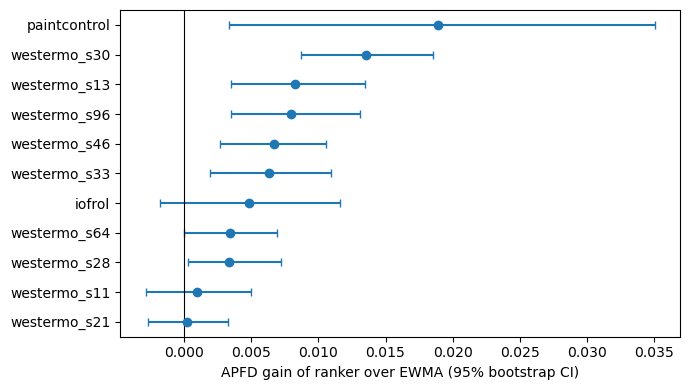

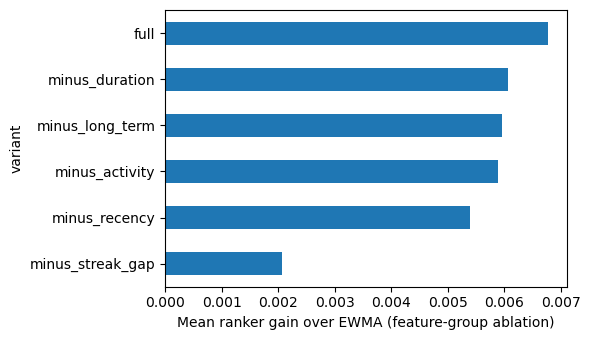

In [43]:
#cell 23 
import matplotlib.pyplot as plt

def boot_ci(x, n=2000, seed=SEED):
    r = np.random.default_rng(seed); x = np.asarray(x)
    m = [r.choice(x, len(x)).mean() for _ in range(n)]
    return np.percentile(m, [2.5, 97.5])

rows = []
for pj, g in PC.groupby("project"):
    d = (g["rank"] - g["ewma"]).dropna()
    lo, hi = boot_ci(d)
    rows.append(dict(project=pj, ewma=g["ewma"].mean(), ranker=g["rank"].mean(),
                     gain=d.mean(), ci_lo=lo, ci_hi=hi, n_cycles=len(d)))
TB = pd.DataFrame(rows).merge(
    S[S.comparison == "rank vs ewma"][["project", "W", "T", "L", "p_holm"]], on="project")
TB = TB.sort_values("gain", ascending=False)
print(TB.round(4).to_string(index=False))
TB.to_csv(os.path.join(OUT_DIR, "table_main.csv"), index=False)
open(os.path.join(OUT_DIR, "table_main.tex"), "w").write(TB.round(4).to_latex(index=False))

fig, ax = plt.subplots(figsize=(7, 4))
y = np.arange(len(TB))
ax.errorbar(TB["gain"], y, xerr=[TB["gain"] - TB["ci_lo"], TB["ci_hi"] - TB["gain"]], fmt="o", capsize=3)
ax.axvline(0, color="k", lw=0.8); ax.set_yticks(y); ax.set_yticklabels(TB["project"])
ax.set_xlabel("APFD gain of ranker over EWMA (95% bootstrap CI)"); ax.invert_yaxis()
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "fig_gain_per_project.png"), dpi=200); plt.show()

fig, ax = plt.subplots(figsize=(6, 3.5))
v = pd.concat([A[["variant", "gain_rank"]].groupby("variant").mean()["gain_rank"]])
v.sort_values().plot.barh(ax=ax); ax.set_xlabel("Mean ranker gain over EWMA (feature-group ablation)")
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "fig_ablation.png"), dpi=200); plt.show()

In [44]:
#cel 24 
def apfdc_one(y, c):
    m = y.sum()
    if m == 0: return np.nan
    c = c.astype(float) + 1e-9
    tot = c.sum(); rest = tot - np.cumsum(c) + c
    pos = np.flatnonzero(y)
    return float((rest[pos] - 0.5 * c[pos]).sum() / (tot * m))

def metrics_cycle(te, score, seed=0):
    rng = np.random.default_rng(seed); rows = {}
    for cy, g in te.groupby("Cycle", sort=True):
        s = score.loc[g.index].to_numpy()
        order = np.lexsort((rng.random(len(g)), -s))
        y = g["y"].to_numpy()[order]; d = g["duration"].to_numpy(float)[order]
        if y.sum() == 0: continue
        rows[cy] = dict(APFD=apfd_one(y), APFDc=apfdc_one(y, d),
                        TCSE30=tcse_one(y, d, 0.3), TCSE50=tcse_one(y, d, 0.5), TCSE70=tcse_one(y, d, 0.7))
    return pd.DataFrame(rows).T

def block_boot(x, block=10, n=2000, seed=SEED):
    x = np.asarray(x); r = np.random.default_rng(seed)
    nb = int(np.ceil(len(x) / block)); blocks = [x[i * block:(i + 1) * block] for i in range(nb)]
    means = [np.concatenate([blocks[j] for j in r.integers(nb, size=nb)]).mean() for _ in range(n)]
    return np.percentile(means, [2.5, 97.5])

LONG = []
for t in PROJS:
    others = [n for n in PROJS if n != t]
    seed_t = SEED + zlib.crc32(t.encode()) % 10000
    tr, grp = build_pool(others, np.random.default_rng(seed_t)); te = prep_test(t)
    m = fit_rank(tr, grp, STAT_BASE, DEFAULT)
    p = pd.Series(m.predict(te[STAT_BASE]), index=te.index)
    scores = {"random": pd.Series(0.0, index=te.index),
              "log_order": -te["first_time"].rank(method="first").fillna(0),
              "ewma": te["ewma"], "ranker": p}
    for k, sc_ in scores.items():
        M = metrics_cycle(te, sc_); M["method"] = k; M["project"] = t; LONG.append(M)
    print(t, "done", flush=True)
L = pd.concat(LONG)
MET = ["APFD", "APFDc", "TCSE30", "TCSE50", "TCSE70"]
print(L.groupby(["method"])[MET].mean().round(4))
pm = L.groupby(["project", "method"])[MET].mean()

rows = []
for pj in PROJS:
    a = L[(L.project == pj) & (L.method == "ranker")][MET]
    b = L[(L.project == pj) & (L.method == "ewma")][MET]
    for k in MET:
        d = (a[k] - b[k]).dropna().to_numpy()
        lo, hi = block_boot(d)
        rows.append(dict(project=pj, metric=k, gain=d.mean(), ci_lo=lo, ci_hi=hi,
                         p=wilcoxon(d).pvalue if (d != 0).any() else 1.0))
G = pd.DataFrame(rows)
G["p_holm"] = G.groupby("metric")["p"].transform(lambda s: multipletests(s, method="holm")[1])
G["ci_excl_0"] = (G.ci_lo > 0) | (G.ci_hi < 0)
print(G.pivot(index="project", columns="metric", values="gain").round(4))
print(G.groupby("metric")[["gain"]].mean().round(4).T)
print(G.groupby("metric")["ci_excl_0"].sum())
G.to_csv(os.path.join(OUT_DIR, "budget_metrics_gains.csv"), index=False)
L.to_csv(os.path.join(OUT_DIR, "percycle_all_metrics.csv"))

paintcontrol done
iofrol done
westermo_s11 done
westermo_s13 done
westermo_s21 done
westermo_s28 done
westermo_s30 done
westermo_s33 done
westermo_s46 done
westermo_s64 done
westermo_s96 done
             APFD   APFDc  TCSE30  TCSE50  TCSE70
method                                           
ewma       0.7672  0.7601  0.5873  0.7173  0.8204
log_order  0.5057  0.4968  0.2544  0.3766  0.5433
random     0.4990  0.4982  0.2461  0.4045  0.5673
ranker     0.7739  0.7657  0.5945  0.7236  0.8276
metric          APFD   APFDc  TCSE30  TCSE50  TCSE70
project                                             
iofrol        0.0049  0.0079  0.0151  0.0073  0.0046
paintcontrol  0.0189  0.0213  0.0276  0.0256  0.0312
westermo_s11  0.0010  0.0032  0.0046 -0.0058  0.0015
westermo_s13  0.0082  0.0015 -0.0036 -0.0074  0.0041
westermo_s21  0.0002  0.0358  0.0549  0.0547  0.0245
westermo_s28  0.0033 -0.0141 -0.0289 -0.0316 -0.0060
westermo_s30  0.0136  0.0104  0.0106  0.0099  0.0132
westermo_s33  0.0063  0.0039  0

In [45]:
#Cell 25: duration-aware scoring (sensitivity analysis)

GAMMAS = [0.0, 0.25, 0.5, 1.0]
rows = []
for t in PROJS:
    others = [n for n in PROJS if n != t]
    seed_t = SEED + zlib.crc32(t.encode()) % 10000
    tr, grp = build_pool(others, np.random.default_rng(seed_t)); te = prep_test(t)
    m = fit_rank(tr, grp, STAT_BASE, DEFAULT)
    p = pd.Series(m.predict(te[STAT_BASE]), index=te.index)
    r_rank = p.groupby(te["Cycle"]).rank(pct=True)
    r_ewma = te["ewma"].groupby(te["Cycle"]).rank(pct=True)
    cost = te["prev_dur_mean"].clip(lower=1.0)
    for g in GAMMAS:
        for name, r_ in (("ranker", r_rank), ("ewma", r_ewma)):
            M = metrics_cycle(te, r_ / cost ** g)
            rows.append(dict(project=t, gamma=g, method=name, **M.mean().to_dict()))
    print(t, "done", flush=True)

Z = pd.DataFrame(rows)
MET2 = ["APFD", "APFDc", "TCSE30", "TCSE50", "TCSE70"]
print(Z.groupby(["method", "gamma"])[MET2].mean().round(4))

W = Z.pivot_table(index=["project", "gamma"], columns="method", values=MET2)
gain = pd.DataFrame({m_: W[(m_, "ranker")] - W[(m_, "ewma")] for m_ in MET2})
print("ranker minus EWMA at the same gamma (mean over projects, # projects positive):")
print(gain.groupby("gamma").agg(["mean", lambda s: (s > 0).sum()]).round(4))

e0 = Z[(Z.method == "ewma") & (Z.gamma == 0.0)].set_index("project")[MET2]
for g in GAMMAS[1:]:
    rg = Z[(Z.method == "ranker") & (Z.gamma == g)].set_index("project")[MET2]
    print(f"cost-aware ranker (gamma={g}) minus plain EWMA:", (rg - e0).mean().round(4).to_dict())
Z.to_csv(os.path.join(OUT_DIR, "cost_aware_sensitivity.csv"), index=False)

paintcontrol done
iofrol done
westermo_s11 done
westermo_s13 done
westermo_s21 done
westermo_s28 done
westermo_s30 done
westermo_s33 done
westermo_s46 done
westermo_s64 done
westermo_s96 done
                APFD   APFDc  TCSE30  TCSE50  TCSE70
method gamma                                        
ewma   0.00   0.7522  0.7482  0.5801  0.7052  0.8036
       0.25   0.7097  0.7630  0.6103  0.7354  0.8140
       0.50   0.6649  0.7512  0.5958  0.7258  0.8136
       1.00   0.5939  0.7209  0.5646  0.6961  0.7893
ranker 0.00   0.7589  0.7549  0.5896  0.7126  0.8122
       0.25   0.7183  0.7658  0.6120  0.7395  0.8172
       0.50   0.6711  0.7538  0.5981  0.7292  0.8164
       1.00   0.6033  0.7241  0.5673  0.7007  0.7917
ranker minus EWMA at the same gamma (mean over projects, # projects positive):
         APFD              APFDc             TCSE30             TCSE50             TCSE70           
         mean <lambda_0>    mean <lambda_0>    mean <lambda_0>    mean <lambda_0>    mean <lambda_

In [46]:
#cell 26 
def fit_rank_seed(tr, grp, feats, prm, sd):
    m = lgb.LGBMRanker(objective="lambdarank", n_estimators=prm["n_estimators"], learning_rate=prm["lr"],
                       num_leaves=prm["num_leaves"], min_child_samples=prm["mcs"], reg_lambda=prm["l2"],
                       subsample=0.8, colsample_bytree=0.8, random_state=sd, verbose=-1)
    return m.fit(tr[feats], tr["y"], group=grp)

rows = []
for sd in range(5):
    for t in PROJS:
        others = [n for n in PROJS if n != t]
        r = np.random.default_rng(1000 * sd + zlib.crc32(t.encode()) % 10000)
        tr, grp = build_pool(others, r); te = prep_test(t)
        m = fit_rank_seed(tr, grp, STAT_BASE, DEFAULT, sd)
        p = pd.Series(m.predict(te[STAT_BASE]), index=te.index)
        rows.append(dict(seed=sd, project=t,
                         ewma=apfd_by_cycle(te, te["ewma"]).mean(),
                         ranker=apfd_by_cycle(te, p).mean()))
    print("seed", sd, "done", flush=True)

V = pd.DataFrame(rows); V["gain"] = V["ranker"] - V["ewma"]
P_ = V.pivot(index="project", columns="seed", values="gain")
print(P_.round(4))
print(pd.DataFrame({"mean": P_.mean(1), "sd": P_.std(1), "seeds_positive": (P_ > 0).sum(1)}).round(4))
per_seed = P_.mean(0)
print("overall gain per seed:", per_seed.round(4).tolist(), "| mean", round(per_seed.mean(), 4), "sd", round(per_seed.std(), 4))
V.to_csv(os.path.join(OUT_DIR, "seed_repeat.csv"), index=False)

seed 0 done
seed 1 done
seed 2 done
seed 3 done
seed 4 done
seed               0       1       2       3       4
project                                             
iofrol        0.0042  0.0015  0.0037  0.0005 -0.0034
paintcontrol  0.0044  0.0120  0.0083  0.0111  0.0113
westermo_s11  0.0034  0.0034  0.0028  0.0033  0.0025
westermo_s13  0.0086  0.0084  0.0103  0.0085  0.0067
westermo_s21  0.0006 -0.0008  0.0011  0.0006  0.0026
westermo_s28  0.0036  0.0029  0.0040  0.0034  0.0044
westermo_s30  0.0122  0.0124  0.0131  0.0122  0.0118
westermo_s33  0.0063  0.0062  0.0069  0.0077  0.0064
westermo_s46  0.0077  0.0063  0.0061  0.0075  0.0053
westermo_s64  0.0058  0.0032  0.0048  0.0036  0.0036
westermo_s96  0.0086  0.0059  0.0080  0.0084  0.0071
                mean      sd  seeds_positive
project                                     
iofrol        0.0013  0.0031               4
paintcontrol  0.0094  0.0031               5
westermo_s11  0.0031  0.0004               5
westermo_s13  0.0085  0.00

In [47]:
#cell 27
import ast
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

raw0 = pd.read_csv(PROJECT_FILES["paintcontrol"]).sort_values("Id").reset_index(drop=True)
lr_lists = [[int(x) for x in str(s).strip("[]").split(",") if x.strip() != ""] for s in raw0["LastResults"]]
raw0["Num_Previous_Execution"] = [max(len(l), 1) for l in lr_lists]
raw0["Failure_Percentage"] = [sum(l) / max(len(l), 1) for l in lr_lists]
raw0["Quarter"] = np.ceil(4 * raw0["Cycle"] / raw0["Cycle"].max()).clip(1, 4)

v, f, q = raw0["Num_Previous_Execution"], raw0["Failure_Percentage"], raw0["Quarter"]
dg, tg = raw0["DurationGroup"], raw0["TimeGroup"]
conds = [(q >= 3) & (v > 100) & (f > 0.2), (q >= 3) & (v > 50) & (f > 0.3), (v < 50) & (f < 0.15),
         (v >= 50) & (v <= 150) & (f >= 0.15) & (f <= 0.30), (v > 150) & (f >= 0.30),
         (dg == 2) & (tg == 0) & (q >= 3), (dg == 2) & (tg == 2), (dg == 1) & (tg == 1),
         (dg == 0) & (tg == 0), (dg == 2) & (tg == 1)]
raw0["Maturity_Level"] = np.select(conds, [3, 3, 1, 2, 3, 2, 3, 2, 1, 2], default=1)

def relevance_vec(d, md, mpe, mf, use_verdict=True):
    D, N, F = d["Duration"], d["Num_Previous_Execution"], d["Failure_Percentage"]
    Q, M = d["Quarter"], d["Maturity_Level"]
    V = (d["Verdict"] > 0) if use_verdict else pd.Series(False, index=d.index)
    main = (D > md) & (N > mpe) & (F > mf)
    cs = [main & (Q > 3), main, ~main & (F > 0.5) & (N > 5), ~main & (F > 0.2) & (N > 40),
          ~main & (F > 0.1) & (N > np.log(100)) & V, ~main & (N > np.log(100)) & V,
          ~main & (M == 3) & V, ~main & (M == 2) & V, ~main & (M == 3) & (F > 0.2)]
    return pd.Series(np.select(cs, [3, 2, 3, 2, 3, 3, 3, 3, 3], default=1), index=d.index)

thr = (raw0["Duration"].std(), raw0["Num_Previous_Execution"].std(), raw0["Failure_Percentage"].std())
raw0["lab_A"] = relevance_vec(raw0, *thr, use_verdict=True)
raw0["lab_B"] = relevance_vec(raw0, *thr, use_verdict=False)
raw0["y"] = (raw0["Verdict"] > 0).astype(int)

cuts = np.sort(raw0["Cycle"].unique()); cut80 = cuts[int(0.8 * len(cuts)) - 1]
trn, tst = raw0[raw0["Cycle"] <= cut80], raw0[raw0["Cycle"] > cut80].copy()
FE = ["Duration", "Num_Previous_Execution", "Failure_Percentage", "Maturity_Level", "Quarter", "DurationGroup", "TimeGroup"]

def rows_apfd(frame, score, seed=0):
    rng = np.random.default_rng(seed); out = []
    for _, g in frame.groupby("Cycle"):
        s = score.loc[g.index].to_numpy()
        o = np.lexsort((rng.random(len(g)), -s)); y = g["y"].to_numpy()[o]
        if y.sum() > 0: out.append(apfd_one(y))
    return float(np.mean(out))

res = []
for lab in ["lab_A", "lab_B"]:
    clf = VotingClassifier([("rf", RandomForestClassifier(200, max_depth=20, random_state=SEED, n_jobs=-1)),
                            ("knn", make_pipeline(StandardScaler(), KNeighborsClassifier(5)))], voting="soft")
    clf.fit(trn[FE], trn[lab])
    P = clf.predict_proba(tst[FE]); ks = clf.classes_
    score = pd.Series((P * ks).sum(1), index=tst.index)
    res.append(dict(labels=lab, accuracy=(clf.predict(tst[FE]) == tst[lab]).mean(),
                    model_APFD=rows_apfd(tst, score),
                    label_rank_APFD=rows_apfd(tst, tst[lab].astype(float)),
                    failure_pct_rank_APFD=rows_apfd(tst, tst["Failure_Percentage"]),
                    random_APFD=np.mean([rows_apfd(tst, pd.Series(0.0, index=tst.index), s) for s in range(10)]),
                    AUC_label_vs_current_verdict=roc_auc_score(tst["y"], tst[lab])))
print(pd.DataFrame(res).round(4).to_string(index=False))
print("train label agreement A vs B:", round((trn["lab_A"] == trn["lab_B"]).mean(), 4))

labels  accuracy  model_APFD  label_rank_APFD  failure_pct_rank_APFD  random_APFD  AUC_label_vs_current_verdict
 lab_A    0.7925      0.5828           0.6296                 0.8519       0.5094                        0.6501
 lab_B    0.8074      0.5535           0.6001                 0.8519       0.5094                        0.5698
train label agreement A vs B: 0.9083


In [48]:
#cell 27 B 
from sklearn.model_selection import KFold, train_test_split, cross_val_score

Xr, yA = raw0[FE], raw0["lab_A"]
rf = RandomForestClassifier(200, max_depth=20, random_state=SEED, n_jobs=-1)

Xtr, Xte, ytr, yte = train_test_split(Xr, yA, test_size=0.2, shuffle=True, random_state=SEED)
acc_shuffled = rf.fit(Xtr, ytr).score(Xte, yte)
cv_shuffled = cross_val_score(rf, Xr, yA, cv=KFold(5, shuffle=True, random_state=SEED)).mean()
cv_blocked = cross_val_score(rf, Xr, yA, cv=KFold(5, shuffle=False)).mean()
acc_chrono = rf.fit(trn[FE], trn["lab_A"]).score(tst[FE], tst["lab_A"])

print(pd.Series({"shuffled 80/20 holdout": acc_shuffled, "shuffled 5-fold CV": cv_shuffled,
                 "time-blocked 5-fold CV": cv_blocked, "chronological 80/20": acc_chrono}).round(4))

shuffled 80/20 holdout    0.9533
shuffled 5-fold CV        0.9559
time-blocked 5-fold CV    0.8384
chronological 80/20       0.8839
dtype: float64


In [49]:
#Cell 28: does maturity add value under a fair test?
from sklearn.linear_model import LogisticRegression

COMP = ["tcm_ec", "tcm_fb", "tcm_ts"]
for nm, c in CT.items():
    if nm.endswith("_ctx"): continue
    c["tcm_ec"] = c["n_prev"] / (c["n_prev"] + 50.0)
    c["tcm_fb"] = c["ew_0.2"]
    c["tcm_ts"] = 1.0 - (c["flips20"] / 19.0).clip(0, 1)
    c["tcm_ahp"] = 0.3708 * c["tcm_ec"] + 0.2922 * c["tcm_fb"] + 0.3370 * c["tcm_ts"]
    c["tcm_eq"] = (c["tcm_ec"] + c["tcm_fb"] + c["tcm_ts"]) / 3.0

rows, coefs, tiers = [], [], []
for t in PROJS:
    others = [n for n in PROJS if n != t]
    seed_t = SEED + zlib.crc32(t.encode()) % 10000
    tr, grp = build_pool(others, np.random.default_rng(seed_t))
    te = prep_test(t).copy()
    lg = LogisticRegression(max_iter=1000).fit(tr[COMP], tr["y"]); coefs.append(lg.coef_[0])
    tr["tcm_learned"] = lg.decision_function(tr[COMP]); te["tcm_learned"] = lg.decision_function(te[COMP])

    variants = {"base": STAT_BASE, "+tcm_ahp": STAT_BASE + ["tcm_ahp"],
                "+tcm_eq": STAT_BASE + ["tcm_eq"], "+tcm_learned": STAT_BASE + ["tcm_learned"]}
    for vn, fs in variants.items():
        m = fit_rank(tr, grp, fs, DEFAULT)
        p = pd.Series(m.predict(te[fs]), index=te.index)
        rows.append(dict(project=t, variant=vn, APFD=apfd_by_cycle(te, p).mean()))
        if vn == "base": p0 = p
    for nm in ["ewma", "tcm_ahp", "tcm_eq", "tcm_learned"]:
        rows.append(dict(project=t, variant="alone_" + nm, APFD=apfd_by_cycle(te, te[nm]).mean()))

    pct = p0.groupby(te["Cycle"]).rank(pct=True)
    tier = pd.cut(pct, [0, 0.5, 0.8, 1.0], labels=["Low", "Medium", "High"], include_lowest=True)
    tt = pd.DataFrame({"tier": tier, "y": te["y"]}).groupby("tier", observed=True)["y"].agg(["mean", "sum", "size"])
    tt["project"] = t; tiers.append(tt.reset_index())
    print(t, "done", flush=True)

R = pd.DataFrame(rows).pivot(index="project", columns="variant", values="APFD")
print(R.round(4))
print(R.mean().round(4))
for v in ["+tcm_ahp", "+tcm_eq", "+tcm_learned"]:
    d = R[v] - R["base"]
    print(v, "gain over base ranker:", round(d.mean(), 4), "| projects positive:", int((d > 0).sum()), "of", len(d))
print("learned TCM coefficients (ec, fb, ts) mean over folds:", np.mean(coefs, axis=0).round(3))
T = pd.concat(tiers)
tot = T.groupby("tier", observed=True).agg(n=("size", "sum"), fails=("sum", "sum"))
tot["fail_rate"] = tot["fails"] / tot["n"]; tot["share_of_all_failures"] = tot["fails"] / tot["fails"].sum()
print(tot.round(4))
R.to_csv(os.path.join(OUT_DIR, "tcm_v2_results.csv")); T.to_csv(os.path.join(OUT_DIR, "tiers_v2.csv"), index=False)

paintcontrol done
iofrol done
westermo_s11 done
westermo_s13 done
westermo_s21 done
westermo_s28 done
westermo_s30 done
westermo_s33 done
westermo_s46 done
westermo_s64 done
westermo_s96 done
variant       +tcm_ahp  +tcm_eq  +tcm_learned  alone_ewma  alone_tcm_ahp  alone_tcm_eq  alone_tcm_learned    base
project                                                                                                          
iofrol          0.6104   0.6097        0.6093      0.6048         0.5936        0.5945             0.6081  0.6097
paintcontrol    0.7868   0.7920        0.7935      0.7820         0.6918        0.7110             0.7963  0.8009
westermo_s11    0.7827   0.7828        0.7813      0.7801         0.7526        0.7579             0.7721  0.7811
westermo_s13    0.7679   0.7678        0.7677      0.7592         0.4695        0.4915             0.7456  0.7674
westermo_s21    0.7067   0.7076        0.7069      0.7076         0.5517        0.5643             0.7047  0.7079
westermo_s

In [50]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

KN_F = ["ew_0.3", "ew_0.5", "ew_0.7", "streak_pass", "streak_fail", "fr_all", "since_fail"]
MEM = ["rank", "rf", "knn", "lr", "ewma"]

def fit_members(tr, grp, seed):
    ms = {}
    ms["rank"] = fit_rank(tr, grp, STAT_BASE, DEFAULT)
    s = tr.sample(min(len(tr), 150000), random_state=seed)
    ms["rf"] = RandomForestClassifier(150, max_depth=12, min_samples_leaf=5,
                                      class_weight="balanced_subsample", n_jobs=-1,
                                      random_state=seed).fit(s[STAT_BASE], s["y"])
    k = tr.sample(min(len(tr), 20000), random_state=seed)
    ms["knn"] = make_pipeline(StandardScaler(), KNeighborsClassifier(25)).fit(k[KN_F], k["y"])
    ms["lr"] = make_pipeline(StandardScaler(), LogisticRegression(max_iter=300)).fit(tr[STAT_BASE], tr["y"])
    return ms

def member_ranks(ms, te):
    raw = {"rank": ms["rank"].predict(te[STAT_BASE]),
           "rf": ms["rf"].predict_proba(te[STAT_BASE])[:, 1],
           "knn": ms["knn"].predict_proba(te[KN_F])[:, 1],
           "lr": ms["lr"].predict_proba(te[STAT_BASE])[:, 1],
           "ewma": te["ewma"].to_numpy()}
    return pd.DataFrame({k: pd.Series(v, index=te.index).groupby(te["Cycle"]).rank(pct=True)
                         for k, v in raw.items()})

rows, pcs, coefs, wts = [], [], [], []
for t in PROJS:
    others = [n for n in PROJS if n != t]
    seed_t = SEED + zlib.crc32(t.encode()) % 10000
    r = np.random.default_rng(seed_t)
    fam_others = [n for n in others if FAM[n] == FAM[t]] or others
    val_name = fam_others[int(r.integers(len(fam_others)))]

    tr_i, g_i = build_pool([n for n in others if n != val_name], r)
    ms_i = fit_members(tr_i, g_i, SEED)
    te_v = prep_test(val_name); Rv = member_ranks(ms_i, te_v)
    apfd_v = {k: apfd_by_cycle(te_v, Rv[k]).mean() for k in MEM}
    w = pd.Series({k: max(apfd_v[k] - 0.5, 0.0) for k in MEM}); w = w / w.sum()
    meta = LogisticRegression(C=1.0, max_iter=500).fit(Rv[MEM], te_v["y"])
    coefs.append(dict(zip(MEM, meta.coef_[0]))); wts.append(w.to_dict())

    tr_f, g_f = build_pool(others, np.random.default_rng(seed_t))
    ms_f = fit_members(tr_f, g_f, SEED)
    te = prep_test(t); Rt = member_ranks(ms_f, te)
    sc = {"ewma": Rt["ewma"], "rank": Rt["rank"], "rf": Rt["rf"], "knn": Rt["knn"], "lr": Rt["lr"],
          "soft_vote": Rt[MEM].mean(axis=1),
          "weighted_vote": (Rt[MEM] * w).sum(axis=1),
          "stack": pd.Series(meta.decision_function(Rt[MEM]), index=te.index)}
    per = pd.DataFrame({k: apfd_by_cycle(te, v) for k, v in sc.items()}); per["project"] = t
    pcs.append(per); print(t, "done", flush=True)

PC2 = pd.concat(pcs)
M2 = PC2.groupby("project").mean(numeric_only=True)
print(M2.round(4)); print(M2.mean().round(4))
G2 = M2.sub(M2["ewma"], axis=0)
print("gain over EWMA (mean, projects positive):")
print(pd.DataFrame({"mean": G2.mean(), "pos": (G2 > 0).sum()}).round(4))
print("ensemble minus ranker:")
for k in ["soft_vote", "weighted_vote", "stack"]:
    d = M2[k] - M2["rank"]; print(k, round(d.mean(), 4), "pos", int((d > 0).sum()))
print("mean stacker coefficients:", pd.DataFrame(coefs).mean().round(3).to_dict())
print("mean voting weights:", pd.DataFrame(wts).mean().round(3).to_dict())
PC2.to_csv(os.path.join(OUT_DIR, "stacking_percycle.csv"))

paintcontrol done
iofrol done
westermo_s11 done
westermo_s13 done
westermo_s21 done
westermo_s28 done
westermo_s30 done
westermo_s33 done
westermo_s46 done
westermo_s64 done
westermo_s96 done
                ewma    rank      rf     knn      lr  soft_vote  weighted_vote   stack
project                                                                               
iofrol        0.6048  0.6097  0.6054  0.5996  0.6043     0.6093         0.6094  0.6078
paintcontrol  0.7820  0.8009  0.7893  0.7694  0.7894     0.7969         0.7977  0.7902
westermo_s11  0.7801  0.7811  0.7758  0.7704  0.7793     0.7825         0.7821  0.7815
westermo_s13  0.7592  0.7674  0.7573  0.7100  0.7651     0.7665         0.7670  0.7594
westermo_s21  0.7076  0.7079  0.7045  0.6920  0.7087     0.7081         0.7081  0.7072
westermo_s28  0.7303  0.7336  0.7262  0.7116  0.7308     0.7321         0.7321  0.7296
westermo_s30  0.7820  0.7955  0.7852  0.7585  0.7916     0.7921         0.7919  0.7876
westermo_s33  0.7900  0.7

In [51]:
import zlib
from scipy.optimize import nnls
from sklearn.ensemble import ExtraTreesClassifier

LIB = ["rk_lambda", "rk_xendcg", "rk_streak", "lgb_bin", "et", "lr", "ewma"]
F_STREAK = ["ewma", "ew_0.3", "ew_0.5", "ew_0.7", "streak_pass", "streak_fail", "since_fail", "flips20", "last1"]

def fit_lib(tr, grp, seed):
    base = dict(n_estimators=200, learning_rate=0.05, num_leaves=8, min_child_samples=30,
                colsample_bytree=0.8, random_state=seed, verbose=-1)
    ms = {}
    ms["rk_lambda"] = lgb.LGBMRanker(objective="lambdarank", **base).fit(tr[STAT_BASE], tr["y"], group=grp)
    ms["rk_xendcg"] = lgb.LGBMRanker(objective="rank_xendcg", **base).fit(tr[STAT_BASE], tr["y"], group=grp)
    ms["rk_streak"] = lgb.LGBMRanker(objective="lambdarank", **base).fit(tr[F_STREAK], tr["y"], group=grp)
    ms["lgb_bin"] = lgb.LGBMClassifier(n_estimators=200, learning_rate=0.05, num_leaves=8, min_child_samples=50,
                                       colsample_bytree=0.8, random_state=seed, verbose=-1).fit(tr[STAT_BASE], tr["y"])
    s = tr.sample(min(len(tr), 80000), random_state=seed)
    ms["et"] = ExtraTreesClassifier(100, min_samples_leaf=10, max_features=0.5, n_jobs=-1,
                                    random_state=seed).fit(s[STAT_BASE], s["y"])
    ms["lr"] = make_pipeline(StandardScaler(), LogisticRegression(max_iter=300)).fit(tr[STAT_BASE], tr["y"])
    return ms

def lib_ranks(ms, te):
    raw = {"rk_lambda": ms["rk_lambda"].predict(te[STAT_BASE]),
           "rk_xendcg": ms["rk_xendcg"].predict(te[STAT_BASE]),
           "rk_streak": ms["rk_streak"].predict(te[F_STREAK]),
           "lgb_bin": ms["lgb_bin"].predict_proba(te[STAT_BASE])[:, 1],
           "et": ms["et"].predict_proba(te[STAT_BASE])[:, 1],
           "lr": ms["lr"].predict_proba(te[STAT_BASE])[:, 1],
           "ewma": te["ewma"].to_numpy()}
    return pd.DataFrame({k: pd.Series(v, index=te.index).groupby(te["Cycle"]).rank(pct=True)
                         for k, v in raw.items()})[LIB]

def make_oof(te, R, r, max_cycles=120):
    fc = te.groupby("Cycle")["y"].sum(); cyc = fc[fc > 0].index.to_numpy()
    if len(cyc) > max_cycles: cyc = np.sort(r.choice(cyc, max_cycles, replace=False))
    m = te["Cycle"].isin(cyc).to_numpy()
    d = te[m]; Rm = R[m].to_numpy(); y = d["y"].to_numpy(); c = d["Cycle"].to_numpy()
    o = np.argsort(c, kind="stable"); Rm, y, c = Rm[o], y[o], c[o]
    cuts = np.flatnonzero(np.r_[True, c[1:] != c[:-1], True])
    return dict(R=Rm, y=y, cuts=cuts, noise=r.random(len(y)))

def oof_apfd(O, w):
    s = O["R"] @ w; out = []
    for a, b in zip(O["cuts"][:-1], O["cuts"][1:]):
        o = np.lexsort((O["noise"][a:b], -s[a:b])); out.append(apfd_one(O["y"][a:b][o]))
    return np.nanmean(out)

def ens_score(OOF, w): return float(np.mean([oof_apfd(O, w) for O in OOF]))

def caruana(OOF, iters=20):
    K = len(LIB); counts = np.zeros(K)
    for _ in range(iters):
        best = None
        for m in range(K):
            c = counts.copy(); c[m] += 1
            sc = ens_score(OOF, c / c.sum())
            if best is None or sc > best[0]: best = (sc, m)
        counts[best[1]] += 1
    return counts / counts.sum()

def nnls_w(OOF):
    X = np.vstack([O["R"] for O in OOF]); y = np.concatenate([O["y"] for O in OOF]).astype(float)
    w, _ = nnls(X, y)
    return w / w.sum() if w.sum() > 0 else np.ones(len(LIB)) / len(LIB)

def hard_pts(R): return (R > 0.8).astype(float) * 2 + ((R > 0.5) & (R <= 0.8)).astype(float)
def combine(R, w, hard=False):
    soft = (R * w).sum(axis=1)
    return (hard_pts(R) * w).sum(axis=1) + 1e-3 * soft if hard else soft

res, W = [], {}
for t in PROJS:
    t0 = time.time()
    others = [n for n in PROJS if n != t]
    seed_t = SEED + zlib.crc32(t.encode()) % 10000
    r = np.random.default_rng(seed_t)
    perm = [str(x) for x in r.permutation(others)]
    groups = [list(map(str, g)) for g in np.array_split(perm, 4)]
    OOF = []
    for G in groups:
        trn = [n for n in others if n not in G]
        tr_i, g_i = build_pool(trn, r); ms = fit_lib(tr_i, g_i, SEED)
        for v in G:
            te_v = prep_test(v); OOF.append(make_oof(te_v, lib_ranks(ms, te_v), r))
    w_u = np.ones(len(LIB)) / len(LIB); w_c = caruana(OOF); w_n = nnls_w(OOF)
    W[t] = dict(caruana=w_c, nnls=w_n)
    tr_f, g_f = build_pool(others, np.random.default_rng(seed_t)); ms = fit_lib(tr_f, g_f, SEED)
    te = prep_test(t); R = lib_ranks(ms, te)
    sc = {"ewma": R["ewma"], "ranker": R["rk_lambda"],
          "soft_equal": combine(R, w_u), "soft_caruana": combine(R, w_c), "soft_nnls": combine(R, w_n),
          "hard_equal": combine(R, w_u, True), "hard_caruana": combine(R, w_c, True)}
    per = pd.DataFrame({k: apfd_by_cycle(te, v) for k, v in sc.items()}); per["project"] = t
    res.append(per); print(t, "done", round(time.time() - t0), "s", flush=True)

PC3 = pd.concat(res); M3 = PC3.groupby("project").mean(numeric_only=True)
print(M3.round(4)); print(M3.mean().round(4))
g_e = M3.sub(M3["ewma"], axis=0); g_r = M3.sub(M3["ranker"], axis=0)
print(pd.DataFrame({"gain_vs_EWMA": g_e.mean(), "pos_vs_EWMA": (g_e > 0).sum(),
                    "gain_vs_ranker": g_r.mean(), "pos_vs_ranker": (g_r > 0).sum()}).round(4))
rows = []
for k in ["soft_equal", "soft_caruana", "soft_nnls", "hard_equal", "hard_caruana"]:
    for pj, g in PC3.groupby("project"):
        d = (g[k] - g["ranker"]).dropna()
        rows.append(dict(method=k, project=pj, diff=d.mean(), p=wilcoxon(d).pvalue if (d != 0).any() else 1.0))
S3 = pd.DataFrame(rows)
S3["p_holm"] = S3.groupby("method")["p"].transform(lambda s: multipletests(s, method="holm")[1])
print(S3.groupby("method").agg(mean_diff=("diff", "mean"), n_sig=("p_holm", lambda s: int((s < .05).sum()))).round(4))
print("mean Caruana weights:", pd.DataFrame({k: v["caruana"] for k, v in W.items()}, index=LIB).T.mean().round(3).to_dict())
print("mean NNLS weights:", pd.DataFrame({k: v["nnls"] for k, v in W.items()}, index=LIB).T.mean().round(3).to_dict())
PC3.to_csv(os.path.join(OUT_DIR, "stacking_v2_percycle.csv"))

paintcontrol done 29 s
iofrol done 27 s
westermo_s11 done 30 s
westermo_s13 done 28 s
westermo_s21 done 28 s
westermo_s28 done 27 s
westermo_s30 done 27 s
westermo_s33 done 28 s
westermo_s46 done 27 s
westermo_s64 done 26 s
westermo_s96 done 25 s
                ewma  ranker  soft_equal  soft_caruana  soft_nnls  hard_equal  hard_caruana
project                                                                                    
iofrol        0.6048  0.6097      0.6091        0.6082     0.6094      0.6103        0.6095
paintcontrol  0.7820  0.8009      0.7975        0.7995     0.7904      0.7982        0.8007
westermo_s11  0.7801  0.7811      0.7830        0.7825     0.7820      0.7830        0.7822
westermo_s13  0.7592  0.7674      0.7681        0.7682     0.7651      0.7671        0.7670
westermo_s21  0.7076  0.7079      0.7082        0.7087     0.7083      0.7083        0.7091
westermo_s28  0.7303  0.7336      0.7332        0.7333     0.7319      0.7335        0.7331
westermo_s30  0.7

In [52]:
for nm, c in CT.items():
    if nm.endswith("_ctx"): continue
    g = c.groupby("Cycle")["y"].agg(["sum", "size"]).sort_index()
    frac = g["sum"] / g["size"]
    c["c_prevfrac"] = c["Cycle"].map(frac.shift(1).fillna(0))
    prior = (g["sum"].cumsum() - g["sum"]) / (g["size"].cumsum() - g["size"]).replace(0, np.nan)
    c["c_projrate"] = c["Cycle"].map(prior.fillna(0))
    c["c_ntests"] = np.log1p(c["Cycle"].map(g["size"]))
    c["c_lognprev"] = np.log1p(c["n_prev"])
CTXF = ["fr_all", "streak_pass", "streak_fail", "since_fail", "prev_nruns",
        "c_lognprev", "c_prevfrac", "c_projrate", "c_ntests"]

def make_oof_df(name, te, R, r, max_cycles=120):
    fc = te.groupby("Cycle")["y"].sum(); cyc = fc[fc > 0].index.to_numpy()
    if len(cyc) > max_cycles: cyc = np.sort(r.choice(cyc, max_cycles, replace=False))
    m = te["Cycle"].isin(cyc).to_numpy()
    d = pd.concat([R[m].reset_index(drop=True),
                   te.loc[m, CTXF + ["y", "Cycle"]].reset_index(drop=True)], axis=1)
    d["gid"] = name + "_" + d["Cycle"].astype(str).str.zfill(6)
    return d

def fit_meta(D, cols, seed, leaves=4):
    D = D.sort_values("gid", kind="stable")
    grp = D.groupby("gid", sort=False).size().to_numpy()
    return lgb.LGBMRanker(objective="lambdarank", n_estimators=150, learning_rate=0.05,
                          num_leaves=leaves, min_child_samples=200, reg_lambda=5.0,
                          colsample_bytree=0.8, random_state=seed, verbose=-1
                          ).fit(D[cols], D["y"], group=grp)

res4 = []
imp_rows = []
for t in PROJS:
    t0 = time.time()
    others = [n for n in PROJS if n != t]
    seed_t = SEED + zlib.crc32(t.encode()) % 10000
    r = np.random.default_rng(seed_t)
    perm = [str(x) for x in r.permutation(others)]
    groups = [list(map(str, gg)) for gg in np.array_split(perm, 4)]
    OOFd = []
    for G in groups:
        trn = [n for n in others if n not in G]
        tr_i, g_i = build_pool(trn, r); ms = fit_lib(tr_i, g_i, SEED)
        for v in G:
            te_v = prep_test(v); OOFd.append(make_oof_df(v, te_v, lib_ranks(ms, te_v), r))
    D = pd.concat(OOFd, ignore_index=True)
    m_plain = fit_meta(D, LIB, SEED)
    m_ctx = fit_meta(D, LIB + CTXF, SEED)
    m_ctx8 = fit_meta(D, LIB + CTXF, SEED, leaves=8)

    tr_f, g_f = build_pool(others, np.random.default_rng(seed_t)); ms = fit_lib(tr_f, g_f, SEED)
    te = prep_test(t); R = lib_ranks(ms, te)
    X = pd.concat([R, te[CTXF]], axis=1)
    sc = {"ewma": R["ewma"], "ranker": R["rk_lambda"], "soft_equal": R[LIB].mean(axis=1),
          "meta_noctx": pd.Series(m_plain.predict(X[LIB]), index=te.index),
          "meta_ctx": pd.Series(m_ctx.predict(X[LIB + CTXF]), index=te.index),
          "meta_ctx8": pd.Series(m_ctx8.predict(X[LIB + CTXF]), index=te.index)}
    per = pd.DataFrame({k: apfd_by_cycle(te, v) for k, v in sc.items()}); per["project"] = t
    res4.append(per)
    imp_rows.append(pd.Series(m_ctx.booster_.feature_importance("gain"), index=LIB + CTXF).pipe(lambda s: s / s.sum()))
    print(t, "done", round(time.time() - t0), "s", flush=True)

PC4 = pd.concat(res4); M4 = PC4.groupby("project").mean(numeric_only=True)
print(M4.round(4)); print(M4.mean().round(4))
g_r = M4.sub(M4["ranker"], axis=0); g_e = M4.sub(M4["ewma"], axis=0)
print(pd.DataFrame({"gain_vs_EWMA": g_e.mean(), "pos_vs_EWMA": (g_e > 0).sum(),
                    "gain_vs_ranker": g_r.mean(), "pos_vs_ranker": (g_r > 0).sum()}).round(4))
rows = []
for k in ["soft_equal", "meta_noctx", "meta_ctx", "meta_ctx8"]:
    for pj, gdf in PC4.groupby("project"):
        d = (gdf[k] - gdf["ranker"]).dropna()
        rows.append(dict(method=k, project=pj, diff=d.mean(),
                         p=wilcoxon(d).pvalue if (d != 0).any() else 1.0))
S4 = pd.DataFrame(rows)
S4["p_holm"] = S4.groupby("method")["p"].transform(lambda s: multipletests(s, method="holm")[1])
print(S4.groupby("method").agg(mean_diff=("diff", "mean"), n_sig=("p_holm", lambda s: int((s < .05).sum()))).round(4))
print("mean gate importance (meta_ctx):")
print(pd.concat(imp_rows, axis=1).mean(axis=1).sort_values(ascending=False).round(3).to_string())
PC4.to_csv(os.path.join(OUT_DIR, "gate_percycle.csv"))

paintcontrol done 24 s
iofrol done 21 s
westermo_s11 done 26 s
westermo_s13 done 26 s
westermo_s21 done 26 s
westermo_s28 done 26 s
westermo_s30 done 26 s
westermo_s33 done 26 s
westermo_s46 done 26 s
westermo_s64 done 26 s
westermo_s96 done 27 s
                ewma  ranker  soft_equal  meta_noctx  meta_ctx  meta_ctx8
project                                                                  
iofrol        0.6048  0.6097      0.6091      0.6104    0.6091     0.6096
paintcontrol  0.7820  0.8009      0.7975      0.8010    0.7999     0.8007
westermo_s11  0.7801  0.7811      0.7831      0.7820    0.7820     0.7821
westermo_s13  0.7592  0.7674      0.7680      0.7679    0.7686     0.7682
westermo_s21  0.7076  0.7079      0.7082      0.7088    0.7089     0.7080
westermo_s28  0.7303  0.7336      0.7331      0.7324    0.7338     0.7335
westermo_s30  0.7820  0.7955      0.7945      0.7941    0.7946     0.7945
westermo_s33  0.7900  0.7963      0.7968      0.7977    0.7981     0.7987
westermo_s46 

In [53]:
def run_gate(sd):
    out = []
    for t in PROJS:
        others = [n for n in PROJS if n != t]
        seed_t = 1000 * sd + zlib.crc32(t.encode()) % 10000
        r = np.random.default_rng(seed_t)
        perm = [str(x) for x in r.permutation(others)]
        groups = [list(map(str, gg)) for gg in np.array_split(perm, 4)]
        OOFd = []
        for G in groups:
            trn = [n for n in others if n not in G]
            tr_i, g_i = build_pool(trn, r); ms = fit_lib(tr_i, g_i, sd)
            for v in G:
                te_v = prep_test(v); OOFd.append(make_oof_df(v, te_v, lib_ranks(ms, te_v), r))
        D = pd.concat(OOFd, ignore_index=True)
        m_no = fit_meta(D, LIB, sd); m_c8 = fit_meta(D, LIB + CTXF, sd, leaves=8)
        tr_f, g_f = build_pool(others, np.random.default_rng(seed_t)); ms = fit_lib(tr_f, g_f, sd)
        te = prep_test(t); R = lib_ranks(ms, te); X = pd.concat([R, te[CTXF]], axis=1)
        sc = {"ewma": R["ewma"], "ranker": R["rk_lambda"],
              "meta_noctx": pd.Series(m_no.predict(X[LIB]), index=te.index),
              "meta_ctx8": pd.Series(m_c8.predict(X[LIB + CTXF]), index=te.index)}
        per = pd.DataFrame({k: apfd_by_cycle(te, v) for k, v in sc.items()})
        per["project"] = t; per["seed"] = sd; out.append(per)
    return pd.concat(out)

runs = []
for sd in range(5):
    runs.append(run_gate(sd)); print("seed", sd, "done", flush=True)
ALL5 = pd.concat(runs)
M5 = ALL5.groupby(["seed", "project"]).mean(numeric_only=True)

for k in ["meta_noctx", "meta_ctx8"]:
    d = (M5[k] - M5["ranker"]).unstack("seed")
    per_seed = d.mean(axis=0)
    print(k, "| gain per seed:", per_seed.round(4).tolist(),
          "| mean", round(per_seed.mean(), 4), "sd", round(per_seed.std(), 4))
    print(pd.DataFrame({"mean_gain": d.mean(axis=1), "sd": d.std(axis=1),
                        "seeds_positive": (d > 0).sum(axis=1)}).round(4))
    pm = d.mean(axis=1)
    print("Wilcoxon over 11 project means p =", round(wilcoxon(pm).pvalue, 4),
          "| projects positive:", int((pm > 0).sum()))
ALL5.to_csv(os.path.join(OUT_DIR, "gate_5seeds_percycle.csv"))

seed 0 done
seed 1 done
seed 2 done
seed 3 done
seed 4 done
meta_noctx | gain per seed: [0.0005, 0.0011, 0.0003, 0.0009, 0.0013] | mean 0.0008 sd 0.0004
              mean_gain      sd  seeds_positive
project                                        
iofrol           0.0019  0.0029               3
paintcontrol     0.0056  0.0026               5
westermo_s11    -0.0002  0.0008               2
westermo_s13     0.0000  0.0017               3
westermo_s21     0.0011  0.0010               4
westermo_s28    -0.0006  0.0007               2
westermo_s30    -0.0007  0.0010               1
westermo_s33     0.0011  0.0009               5
westermo_s46     0.0012  0.0005               5
westermo_s64     0.0009  0.0014               4
westermo_s96    -0.0013  0.0004               0
Wilcoxon over 11 project means p = 0.2061 | projects positive: 7
meta_ctx8 | gain per seed: [0.0003, 0.0014, 0.0005, 0.0011, 0.0009] | mean 0.0009 sd 0.0004
              mean_gain      sd  seeds_positive
project           

paintcontrol done 11 s
iofrol done 9 s
westermo_s11 done 10 s
westermo_s13 done 10 s
westermo_s21 done 10 s
westermo_s28 done 10 s
westermo_s30 done 11 s
westermo_s33 done 10 s
westermo_s46 done 11 s
westermo_s64 done 11 s
westermo_s96 done 11 s
                 MI  perm_APFD_drop  folds_perm_top5  mean_abs_SHAP  SHAP_share  univariate_APFD
streak_pass  0.1088          0.0287               11         0.8579      0.3688           0.7426
fr_all       0.0694          0.0035                9         0.2544      0.1058           0.7017
streak_fail  0.0826          0.0030                6         0.0993      0.0434           0.6554
ew_0.2       0.1311          0.0021                3         0.0230      0.0094           0.7529
flips20      0.0276          0.0018                5         0.0580      0.0240           0.5941
ew_0.3       0.1333          0.0017                4         0.1958      0.0796           0.7532
dur_ratio    0.0265          0.0013                2         0.0492      0.

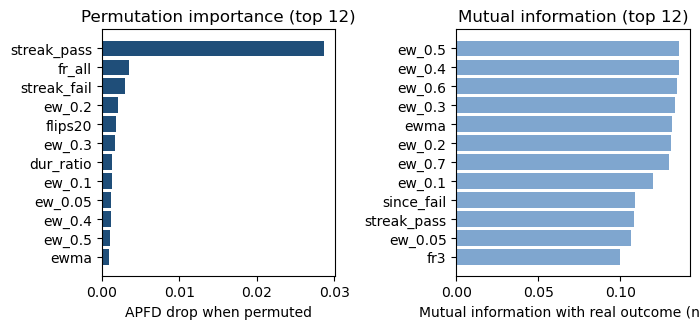

In [54]:
from sklearn.feature_selection import mutual_info_classif
from scipy.stats import spearmanr
import zlib, matplotlib.pyplot as plt

ALPHAS_ = [0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7]
GRP = {"recency": ["last1", "fr3", "fr5", "fr10", "fr20", "ewma"] + [f"ew_{a}" for a in ALPHAS_],
       "long_term": ["fr_all"], "streak_gap": ["streak_fail", "streak_pass", "since_fail", "flips20"],
       "duration": ["dur_ratio"], "activity": ["prev_nruns"]}
TWIN = {"ewma": ["ewma", "ew_0.2"], "ew_0.2": ["ewma", "ew_0.2"]}

def sample_cycles(te, k=200, seed=0):
    fc = te.groupby("Cycle")["y"].sum(); cyc = fc[fc > 0].index.to_numpy()
    if len(cyc) > k: cyc = np.sort(np.random.default_rng(seed).choice(cyc, k, replace=False))
    return te[te["Cycle"].isin(cyc)]

def apfd_of(model, frame, X):
    return apfd_by_cycle(frame, pd.Series(model.predict(X), index=frame.index)).mean()

steps = [("ewma only", ["ewma"])]
cum = ["ewma"]
for gname in ["recency", "streak_gap", "long_term", "duration", "activity"]:
    cum = cum + [f for f in GRP[gname] if f not in cum]
    steps.append(("+ " + gname, list(cum)))

R_pi, R_grp, R_mi, R_shap, R_uni, R_inc = [], [], [], [], [], []
for t in PROJS:
    t0 = time.time()
    others = [n for n in PROJS if n != t]
    seed_t = SEED + zlib.crc32(t.encode()) % 10000
    rng = np.random.default_rng(seed_t)
    tr, grp = build_pool(others, np.random.default_rng(seed_t))
    te = prep_test(t); tes = sample_cycles(te, 200, seed_t)
    model = fit_rank(tr, grp, STAT_BASE, DEFAULT)
    base = apfd_of(model, tes, tes[STAT_BASE])

    pi = {}
    for f in STAT_BASE:
        cols = TWIN.get(f, [f]); drops = []
        for _ in range(2):
            X = tes[STAT_BASE].copy(); idx = rng.permutation(len(X))
            for c_ in cols: X[c_] = X[c_].to_numpy()[idx]
            drops.append(base - apfd_of(model, tes, X))
        pi[f] = np.mean(drops)
    R_pi.append(pd.Series(pi, name=t))

    gp = {}
    for g_, fs in GRP.items():
        X = tes[STAT_BASE].copy(); idx = rng.permutation(len(X))
        for c_ in fs: X[c_] = X[c_].to_numpy()[idx]
        gp[g_] = base - apfd_of(model, tes, X)
    R_grp.append(pd.Series(gp, name=t))

    s = tr.sample(min(len(tr), 30000), random_state=SEED)
    R_mi.append(pd.Series(mutual_info_classif(s[STAT_BASE], s["y"], random_state=SEED), index=STAT_BASE, name=t))

    Xs = tes[STAT_BASE].sample(min(len(tes), 30000), random_state=0)
    contrib = model.booster_.predict(Xs, pred_contrib=True)[:, :-1]
    R_shap.append(pd.Series(np.abs(contrib).mean(axis=0), index=STAT_BASE, name=t))

    uni = {}
    for f in STAT_BASE:
        sign = np.sign(spearmanr(s[f], s["y"])[0]) or 1.0
        uni[f] = apfd_by_cycle(tes, sign * tes[f]).mean()
    R_uni.append(pd.Series(uni, name=t))

    inc = {}
    for name, fs in steps:
        m = fit_rank(tr, grp, fs, DEFAULT); inc[name] = apfd_of(m, tes, tes[fs])
    inc["EWMA baseline"] = apfd_by_cycle(tes, tes["ewma"]).mean(); inc["full model"] = base
    R_inc.append(pd.Series(inc, name=t))
    print(t, "done", round(time.time() - t0), "s", flush=True)

PI = pd.concat(R_pi, axis=1); GPI = pd.concat(R_grp, axis=1)
MI = pd.concat(R_mi, axis=1); SH = pd.concat(R_shap, axis=1)
UNI = pd.concat(R_uni, axis=1); INC = pd.concat(R_inc, axis=1)

tab = pd.DataFrame({"MI": MI.mean(axis=1), "perm_APFD_drop": PI.mean(axis=1),
                    "folds_perm_top5": (PI.rank(ascending=False) <= 5).sum(axis=1),
                    "mean_abs_SHAP": SH.mean(axis=1), "SHAP_share": (SH / SH.sum()).mean(axis=1),
                    "univariate_APFD": UNI.mean(axis=1)}).sort_values("perm_APFD_drop", ascending=False)
print(tab.round(4).to_string())
print("\nGroup permutation importance (APFD drop):"); print(GPI.mean(axis=1).sort_values(ascending=False).round(4))
print("\nIncremental build-up (mean APFD on sampled test cycles):"); print(INC.mean(axis=1).round(4))

pooled = pd.concat([CT[n][STAT_BASE].sample(min(5000, len(CT[n])), random_state=0) for n in PROJS])
cm = pooled.corr(method="spearman").abs()
pairs = [(a, b, round(cm.loc[a, b], 3)) for i, a in enumerate(STAT_BASE) for b in STAT_BASE[i + 1:] if cm.loc[a, b] > 0.9]
print("\nHighly correlated pairs (|rho|>0.9):", pairs)

for nm, d in [("fi_table", tab), ("fi_groups", GPI.mean(axis=1).to_frame("perm_drop")), ("fi_incremental", INC.mean(axis=1).to_frame("APFD"))]:
    d.to_csv(os.path.join(OUT_DIR, nm + ".csv"))

fig, axs = plt.subplots(1, 2, figsize=(7.1, 3.4))
top = tab.head(12)[::-1]
axs[0].barh(top.index, top["perm_APFD_drop"], color="#1f4e79"); axs[0].set_xlabel("APFD drop when permuted")
axs[0].set_title("Permutation importance (top 12)")
mi_s = tab.sort_values("MI", ascending=False).head(12)[::-1]
axs[1].barh(mi_s.index, mi_s["MI"], color="#7fa6cf"); axs[1].set_xlabel("Mutual information with real outcome (nats)")
axs[1].set_title("Mutual information (top 12)")
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "fig_importance.png"), dpi=300); plt.show()

In [55]:
from scipy.stats import wilcoxon
import zlib, time

DUP = {"ew_0.2", "since_fail"}
VARIANTS = {
    "full (21 columns)": list(STAT_BASE),
    "distinct (19)": [f for f in STAT_BASE if f not in DUP],
    "compact-8": ["ewma", "ew_0.05", "ew_0.5", "fr_all", "streak_pass", "streak_fail", "flips20", "dur_ratio"],
    "compact-5": ["ewma", "fr_all", "streak_pass", "streak_fail", "flips20"],
    "compact-4 (no flips)": ["ewma", "fr_all", "streak_pass", "streak_fail"],
}
SEEDS34 = [0, 1, 2]

rows = []
for s in SEEDS34:
    for t in PROJS:
        t0 = time.time()
        others = [n for n in PROJS if n != t]
        seed_t = SEED + s + zlib.crc32(t.encode()) % 10000
        tr, grp = build_pool(others, np.random.default_rng(seed_t))
        te = prep_test(t)
        base = apfd_by_cycle(te, te["ewma"]).mean()
        for name, feats in VARIANTS.items():
            m = fit_rank(tr, grp, feats, DEFAULT)
            sc = pd.Series(m.predict(te[feats]), index=te.index)
            rows.append({"seed": s, "project": t, "variant": name,
                         "apfd": apfd_by_cycle(te, sc).mean(), "ewma": base})
    print("seed", s, "done", flush=True)

R = pd.DataFrame(rows)
R["gain"] = R["apfd"] - R["ewma"]

per_seed = R.groupby(["variant", "seed"])["gain"].mean().unstack()
per_proj = R.groupby(["variant", "project"])["gain"].mean().unstack(0)
full = "full (21 columns)"

out = []
for v in VARIANTS:
    d = (per_proj[v] - per_proj[full])
    try:
        p = wilcoxon(per_proj[v], per_proj[full]).pvalue if v != full else np.nan
    except ValueError:
        p = np.nan
    out.append({"variant": v, "n_features": len(VARIANTS[v]),
                "mean_gain_vs_EWMA": per_proj[v].mean(),
                "seed_sd": per_seed.loc[v].std(),
                "projects_positive": int((per_proj[v] > 0).sum()),
                "diff_vs_full": d.mean(),
                "projects_better_than_full": int((d > 0).sum()) if v != full else np.nan,
                "wilcoxon_p_vs_full": p})
res = pd.DataFrame(out).set_index("variant")
print(res.round(4).to_string())
print("\nper-seed mean gain:\n", per_seed.round(4).to_string())
print("\nper-project mean gain:\n", per_proj.round(4).to_string())

res.to_csv(os.path.join(OUT_DIR, "feature_subsets.csv"))
per_proj.to_csv(os.path.join(OUT_DIR, "feature_subsets_by_project.csv"))

seed 0 done
seed 1 done
seed 2 done
                      n_features  mean_gain_vs_EWMA  seed_sd  projects_positive  diff_vs_full  projects_better_than_full  wilcoxon_p_vs_full
variant                                                                                                                                     
full (21 columns)             21             0.0062   0.0009                 11        0.0000                        NaN                 NaN
distinct (19)                 19             0.0060   0.0006                 11       -0.0002                        4.0              0.2061
compact-8                      8             0.0056   0.0007                 11       -0.0006                        3.0              0.0830
compact-5                      5             0.0052   0.0002                 11       -0.0010                        3.0              0.1016
compact-4 (no flips)           4             0.0040   0.0006                 10       -0.0021                        2

In [56]:
from scipy.stats import wilcoxon
import zlib

SEEDS5 = [0, 1, 2, 3, 4]

def holm(ps):
    ps = np.asarray(ps); o = np.argsort(ps); adj = np.empty(len(ps)); run = 0
    for i, j in enumerate(o):
        run = max(run, (len(ps) - i) * ps[j]); adj[j] = min(1, run)
    return adj

def lopo_percycle(variants, seeds=SEEDS5):
    recs = []
    for s in seeds:
        for t in PROJS:
            others = [n for n in PROJS if n != t]
            seed_t = SEED + s + zlib.crc32(t.encode()) % 10000
            tr, grp = build_pool(others, np.random.default_rng(seed_t))
            te = prep_test(t)
            r = apfd_by_cycle(te, te["ewma"])
            recs.append(pd.DataFrame({"seed": s, "project": t, "variant": "EWMA", "cycle": r.index, "apfd": r.values}))
            for name, feats in variants.items():
                m = fit_rank(tr, grp, feats, DEFAULT)
                r = apfd_by_cycle(te, pd.Series(m.predict(te[feats]), index=te.index))
                recs.append(pd.DataFrame({"seed": s, "project": t, "variant": name, "cycle": r.index, "apfd": r.values}))
    return pd.concat(recs, ignore_index=True)

df = lopo_percycle({"Ranker": list(STAT_BASE)})
cy = df.groupby(["variant", "project", "cycle"])["apfd"].mean().reset_index()   # average over seeds
wide = cy.pivot_table(index=["project", "cycle"], columns="variant", values="apfd").reset_index()
wide["diff"] = wide["Ranker"] - wide["EWMA"]

rng = np.random.default_rng(0); out = []
for p, g in wide.groupby("project"):
    d = g["diff"].to_numpy()
    boots = [rng.choice(d, len(d)).mean() for _ in range(2000)]
    nz = d[d != 0]
    out.append({"project": p, "EWMA": g["EWMA"].mean(), "Ranker": g["Ranker"].mean(), "gain": d.mean(),
                "lo": np.percentile(boots, 2.5), "hi": np.percentile(boots, 97.5),
                "W": int((d > 0).sum()), "T": int((d == 0).sum()), "L": int((d < 0).sum()),
                "p": wilcoxon(nz).pvalue if len(nz) > 0 else 1.0})
T4 = pd.DataFrame(out).set_index("project")
T4["p_holm"] = holm(T4["p"].to_numpy())

seed_gain = (df[df.variant == "Ranker"].groupby(["seed", "project"])["apfd"].mean()
             - df[df.variant == "EWMA"].groupby(["seed", "project"])["apfd"].mean()).unstack()
T4["seeds_positive"] = (seed_gain > 0).sum(axis=0)
print(T4.sort_values("gain", ascending=False).round(4).to_string())
print("mean EWMA %.4f | mean Ranker %.4f | mean gain %.4f | per-seed gains %s | seed sd %.4f" % (
    T4.EWMA.mean(), T4.Ranker.mean(), T4.gain.mean(), seed_gain.mean(axis=1).round(4).tolist(), seed_gain.mean(axis=1).std()))

                EWMA  Ranker    gain      lo      hi    W    T    L       p  p_holm  seeds_positive
project                                                                                            
westermo_s30  0.7820  0.7950  0.0130  0.0085  0.0180  270  655  187  0.0000  0.0000               5
paintcontrol  0.7820  0.7927  0.0107 -0.0029  0.0251   55   99   65  0.9927  0.9927               5
westermo_s13  0.7592  0.7683  0.0092  0.0044  0.0142  254  446  189  0.0007  0.0064               5
westermo_s96  0.7354  0.7428  0.0074  0.0034  0.0121  124  350   81  0.0001  0.0012               5
westermo_s46  0.7922  0.7996  0.0074  0.0036  0.0115  330  670  269  0.0011  0.0090               5
westermo_s33  0.7900  0.7971  0.0071  0.0031  0.0113  233  665  213  0.0100  0.0702               5
westermo_s64  0.8101  0.8141  0.0040  0.0008  0.0074  251  626  205  0.0249  0.1496               5
iofrol        0.6048  0.6084  0.0036 -0.0030  0.0100   72   84   62  0.1802  0.7206               5


                  n_features    gain  seed_sd  projects_pos  diff_vs_full  retention  p_vs_full
variant                                                                                        
Compact-4                  4  0.0043   0.0006            10       -0.0019     0.6991     0.0186
Compact-5                  5  0.0053   0.0002            11       -0.0009     0.8612     0.2061
Compact-8                  8  0.0056   0.0006            11       -0.0006     0.9071     0.0420
Distinct (19)             19  0.0061   0.0005            11       -0.0001     0.9901     0.7646
Full                      21  0.0062   0.0007            11        0.0000     1.0000        NaN
Minus activity            20  0.0059   0.0007            11       -0.0003     0.9501     0.3652
Minus duration            20  0.0059   0.0003            11       -0.0003     0.9575     0.3203
Minus long_term           20  0.0053   0.0005            10       -0.0008     0.8662     0.0244
Minus recency              7  0.0058   0

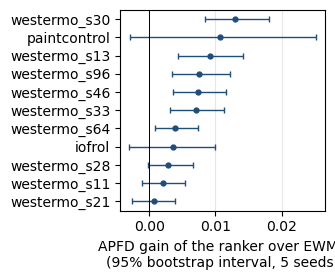

In [57]:
GRP = {"recency": ["last1", "fr3", "fr5", "fr10", "fr20", "ewma"] + [f"ew_{a}" for a in [0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7]],
       "long_term": ["fr_all"], "streak_gap": ["streak_fail", "streak_pass", "since_fail", "flips20"],
       "duration": ["dur_ratio"], "activity": ["prev_nruns"]}
V = {"Full": list(STAT_BASE),
     "Distinct (19)": [f for f in STAT_BASE if f not in {"ew_0.2", "since_fail"}],
     "Compact-8": ["ewma", "ew_0.05", "ew_0.5", "fr_all", "streak_pass", "streak_fail", "flips20", "dur_ratio"],
     "Compact-5": ["ewma", "fr_all", "streak_pass", "streak_fail", "flips20"],
     "Compact-4": ["ewma", "fr_all", "streak_pass", "streak_fail"]}
for g_, fs in GRP.items():
    V["Minus " + g_] = [f for f in STAT_BASE if f not in fs]

dfv = lopo_percycle(V)
cyv = dfv.groupby(["variant", "project", "cycle"])["apfd"].mean().reset_index()
pm = cyv.groupby(["variant", "project"])["apfd"].mean().unstack(0)
gain = pm.sub(pm["EWMA"], axis=0).drop(columns="EWMA")
sp = dfv.groupby(["seed", "project", "variant"])["apfd"].mean().unstack("variant")
sg = sp.sub(sp["EWMA"], axis=0).drop(columns="EWMA").groupby("seed").mean()

rows = []
for v in gain.columns:
    d = gain[v] - gain["Full"]
    p = wilcoxon(gain[v], gain["Full"]).pvalue if v != "Full" else np.nan
    rows.append({"variant": v, "n_features": len(V[v]), "gain": gain[v].mean(), "seed_sd": sg[v].std(),
                 "projects_pos": int((gain[v] > 0).sum()), "diff_vs_full": d.mean(),
                 "retention": gain[v].mean() / gain["Full"].mean(), "p_vs_full": p})
S = pd.DataFrame(rows).set_index("variant")
print(S.round(4).to_string())
S.to_csv(os.path.join(OUT_DIR, "subsets_ablation_5seed.csv"))

import matplotlib.pyplot as plt
Tf = T4.sort_values("gain", ascending=False)
fig, ax = plt.subplots(figsize=(3.45, 2.9)); y = np.arange(len(Tf))
ax.errorbar(Tf["gain"], y, xerr=[Tf["gain"] - Tf["lo"], Tf["hi"] - Tf["gain"]], fmt="o", ms=3.5, capsize=2, color="#1f4e79", lw=1)
ax.axvline(0, color="k", lw=0.7); ax.set_yticks(y); ax.set_yticklabels(Tf.index); ax.invert_yaxis()
ax.set_xlabel("APFD gain of the ranker over EWMA\n(95% bootstrap interval, 5 seeds)"); ax.grid(axis="x", alpha=.3)
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "fig_forest.png"), dpi=300); plt.show()

In [58]:
import inspect
print(inspect.getsource(apfd_by_cycle))
te = prep_test("paintcontrol")
print(apfd_by_cycle(te, te["ewma"]).mean(), apfd_by_cycle(te, te["ewma"]).mean())

def apfd_by_cycle(frame, score, seed=0):
    rng = np.random.default_rng(seed)
    out = {}
    for c, g in frame.groupby("Cycle", sort=True):
        s = score.loc[g.index].to_numpy()
        order = np.lexsort((rng.random(len(g)), -s))
        out[c] = apfd_one(g["y"].to_numpy()[order])
    return pd.Series(out)

0.7820284575334979 0.7820284575334979


In [59]:
"""
M1 revision helpers.

1. A leakage-safe online loop for published learners (RETECS, COLEMAN, ...):
   each cycle is ranked BEFORE its verdicts and actual durations can be read,
   and any early access raises VerdictAccessError (a mechanical check).
2. Practical-size metrics: APFD, APFDc, mean failing-test position,
   positions gained vs a baseline, time to first failure, Vargha-Delaney A12,
   paired Wilcoxon with Holm correction.

Nothing here depends on a specific dataset. Map your own cycle records onto
`Cycle` (test ids, history features computed from earlier cycles only,
verdicts 1=fail/0=pass, and the cycle's actual durations for evaluation).
"""
from __future__ import annotations

from dataclasses import dataclass, field, replace
from typing import Callable, Mapping, Protocol, Sequence

import numpy as np
from scipy.stats import wilcoxon


# --------------------------------------------------------------------------
# 1. Leakage-safe online protocol
# --------------------------------------------------------------------------
class VerdictAccessError(RuntimeError):
    """Raised when a learner reads outcomes of a cycle it has not ranked yet."""


@dataclass
class Cycle:
    cycle_id: str
    timestamp: float                      # ordering key (use completion time if available)
    tests: list[str]
    features: dict[str, dict]             # per-test features from EARLIER cycles only
    _verdicts: dict[str, int] = field(repr=False, default_factory=dict)
    _durations: dict[str, float] = field(repr=False, default_factory=dict)
    _released: bool = field(repr=False, default=False)

    def _guard(self) -> None:
        if not self._released:
            raise VerdictAccessError(
                f"outcomes of cycle {self.cycle_id} were read before its ranking was submitted"
            )

    @property
    def verdicts(self) -> dict[str, int]:
        self._guard()
        return self._verdicts

    @property
    def durations(self) -> dict[str, float]:
        """Actual durations in THIS cycle: outcome data, guarded like verdicts."""
        self._guard()
        return self._durations

    def fresh(self) -> "Cycle":
        return replace(self, _released=False)

    def _release(self) -> None:
        self._released = True


class OnlineLearner(Protocol):
    def rank(self, cycle: Cycle) -> list[str]: ...
    def update(self, cycle: Cycle) -> None: ...


def run_online(
    learner: OnlineLearner,
    cycles: Sequence[Cycle],
    eval_from: float,
) -> list[dict]:
    """Prequential loop: rank -> release outcomes -> score -> update.

    Cycles before `eval_from` are still fed to the learner (so it warms up on
    the same history your ranker trains on) but are not scored. All methods
    must be scored on the same evaluation cycles.
    """
    ts = [c.timestamp for c in cycles]
    if any(b < a for a, b in zip(ts, ts[1:])):
        raise ValueError("cycles must be in non-decreasing timestamp order")

    results = []
    for raw in cycles:
        c = raw.fresh()
        order = learner.rank(c)
        if sorted(order) != sorted(c.tests):
            raise ValueError(f"cycle {c.cycle_id}: ranking is not a permutation of the cycle's tests")
        c._release()
        if c.timestamp >= eval_from:
            r = score_cycle(order, c.verdicts, c.durations)
            if r is not None:
                r["cycle_id"] = c.cycle_id
                results.append(r)
        learner.update(c)
    return results


# --------------------------------------------------------------------------
# 2. Ordering helpers (explicit, seeded tie-breaking)
# --------------------------------------------------------------------------
def order_by_scores(
    tests: Sequence[str], scores: Mapping[str, float], rng: np.random.Generator
) -> list[str]:
    """Descending score; ties broken by a random key from `rng`."""
    keys = rng.random(len(tests))
    idx = sorted(range(len(tests)), key=lambda i: (-scores[tests[i]], keys[i]))
    return [tests[i] for i in idx]


def order_lexicographic(
    tests: Sequence[str],
    primary: Mapping[str, float],
    secondary: Mapping[str, float],
    rng: np.random.Generator,
) -> list[str]:
    """Descending primary, then descending secondary, then random key."""
    keys = rng.random(len(tests))
    idx = sorted(
        range(len(tests)),
        key=lambda i: (-primary[tests[i]], -secondary[tests[i]], keys[i]),
    )
    return [tests[i] for i in idx]


# --------------------------------------------------------------------------
# 3. Per-cycle metrics
# --------------------------------------------------------------------------
def _fail_positions(order: Sequence[str], verdicts: Mapping[str, int]) -> np.ndarray:
    return np.array([i + 1 for i, t in enumerate(order) if verdicts[t] == 1])


def apfd(order: Sequence[str], verdicts: Mapping[str, int]) -> float | None:
    n = len(order)
    tf = _fail_positions(order, verdicts)
    m = len(tf)
    if m == 0:
        return None  # undefined: report how many cycles were skipped
    return 1.0 - tf.sum() / (n * m) + 1.0 / (2 * n)


def apfdc(
    order: Sequence[str], verdicts: Mapping[str, int], durations: Mapping[str, float]
) -> float | None:
    """Cost-cognizant APFD (one fault per failing test, unit severity)."""
    t = np.array([durations[x] for x in order], dtype=float)
    tf = _fail_positions(order, verdicts)
    m = len(tf)
    if m == 0 or t.sum() == 0:
        return None
    suffix = np.cumsum(t[::-1])[::-1]  # suffix[j] = sum_{k>=j} t_k (0-based)
    num = sum(suffix[p - 1] - 0.5 * t[p - 1] for p in tf)
    return float(num / (t.sum() * m))


def mean_fail_position(order: Sequence[str], verdicts: Mapping[str, int]) -> float | None:
    tf = _fail_positions(order, verdicts)
    return float(tf.mean()) if len(tf) else None


def time_to_first_failure(
    order: Sequence[str], verdicts: Mapping[str, int], durations: Mapping[str, float]
) -> float | None:
    elapsed = 0.0
    for t in order:
        elapsed += durations[t]
        if verdicts[t] == 1:
            return elapsed
    return None


def score_cycle(
    order: Sequence[str], verdicts: Mapping[str, int], durations: Mapping[str, float]
) -> dict | None:
    a = apfd(order, verdicts)
    if a is None:
        return None
    return {
        "n": len(order),
        "m": int(sum(verdicts[t] for t in order)),
        "apfd": a,
        "apfdc": apfdc(order, verdicts, durations),
        "mean_fail_pos": mean_fail_position(order, verdicts),
        "ttff": time_to_first_failure(order, verdicts, durations),
    }


def baseline_over_seeds(
    make_order: Callable[[np.random.Generator], list[str]],
    verdicts: Mapping[str, int],
    durations: Mapping[str, float],
    seeds: Sequence[int] = range(30),
) -> dict:
    """Average a tie-dependent baseline (e.g. EWMA) over tie-break seeds."""
    rows = [score_cycle(make_order(np.random.default_rng(s)), verdicts, durations) for s in seeds]
    rows = [r for r in rows if r is not None]
    keys = ["apfd", "apfdc", "mean_fail_pos", "ttff"]
    return {k: float(np.mean([r[k] for r in rows if r[k] is not None])) for k in keys}


# --------------------------------------------------------------------------
# 4. System-level effect sizes and tests
# --------------------------------------------------------------------------
def a12(x: Sequence[float], y: Sequence[float]) -> float:
    """Vargha-Delaney A12: P(X > Y) + 0.5 P(X = Y). Unpaired by definition."""
    x, y = np.asarray(x, float), np.asarray(y, float)
    gt = (x[:, None] > y[None, :]).sum()
    eq = (x[:, None] == y[None, :]).sum()
    return float((gt + 0.5 * eq) / (len(x) * len(y)))


def paired_summary(method: Sequence[float], baseline: Sequence[float]) -> dict:
    """Per-system summary on cycle-paired values (same cycles, same order)."""
    d = np.asarray(method, float) - np.asarray(baseline, float)
    nonzero = d[d != 0]
    p = float(wilcoxon(d, zero_method="zsplit").pvalue) if len(nonzero) else 1.0
    return {
        "mean_diff": float(d.mean()),
        "median_diff": float(np.median(d)),
        "share_cycles_better": float((d > 0).mean()),
        "share_cycles_worse": float((d < 0).mean()),
        "a12": a12(method, baseline),
        "wilcoxon_p": p,
    }


def holm(pvalues: Mapping[str, float]) -> dict[str, float]:
    """Holm-adjusted p-values across systems."""
    items = sorted(pvalues.items(), key=lambda kv: kv[1])
    m, running, out = len(items), 0.0, {}
    for i, (k, p) in enumerate(items):
        running = max(running, min(1.0, (m - i) * p))
        out[k] = running
    return out


# --------------------------------------------------------------------------
# 5. Self-test on synthetic data
# --------------------------------------------------------------------------
class _EWMALearner:
    """Toy online learner: EWMA of past failures, random tie-break."""

    def __init__(self, alpha: float = 0.3, seed: int = 0):
        self.alpha, self.rng, self.ewma = alpha, np.random.default_rng(seed), {}

    def rank(self, cycle: Cycle) -> list[str]:
        scores = {t: self.ewma.get(t, 0.0) for t in cycle.tests}
        return order_by_scores(cycle.tests, scores, self.rng)

    def update(self, cycle: Cycle) -> None:
        for t, v in cycle.verdicts.items():
            self.ewma[t] = self.alpha * v + (1 - self.alpha) * self.ewma.get(t, 0.0)


class _PeekingLearner(_EWMALearner):
    def rank(self, cycle: Cycle) -> list[str]:
        _ = cycle.verdicts  # leakage: must raise
        return super().rank(cycle)


def _synthetic(n_cycles=200, n_tests=55, seed=1) -> list[Cycle]:
    rng = np.random.default_rng(seed)
    tests = [f"t{i}" for i in range(n_tests)]
    base = rng.beta(0.5, 8, n_tests)          # sticky, skewed failure rates
    dur = rng.lognormal(3, 0.6, n_tests)      # seconds
    out, prev = [], np.zeros(n_tests)
    for k in range(n_cycles):
        p = np.clip(base + 0.4 * prev, 0, 0.95)
        v = (rng.random(n_tests) < p).astype(int)
        out.append(Cycle(
            cycle_id=f"c{k}", timestamp=float(k), tests=list(tests), features={},
            _verdicts=dict(zip(tests, v.tolist())),
            _durations=dict(zip(tests, (dur * rng.uniform(0.9, 1.1, n_tests)).tolist())),
        ))
        prev = v
    return out


if __name__ == "__main__":
    cycles = _synthetic()

    try:
        run_online(_PeekingLearner(), cycles, eval_from=100)
        raise SystemExit("FAIL: leakage was not detected")
    except VerdictAccessError as e:
        print("leakage check OK ->", e)

    res = run_online(_EWMALearner(), cycles, eval_from=100)
    print(f"scored cycles: {len(res)} (cycles without failures skipped)")
    print("mean APFD  :", round(np.mean([r['apfd'] for r in res]), 4))
    print("mean APFDc :", round(np.mean([r['apfdc'] for r in res]), 4))

    # Random baseline on the same evaluation cycles, averaged over seeds
    rnd = []
    for c in cycles[100:]:
        c2 = c.fresh(); c2._release()
        if apfd(c2.tests, c2.verdicts) is None:
            continue
        rnd.append(baseline_over_seeds(
            lambda g, c2=c2: list(g.permutation(c2.tests)), c2.verdicts, c2.durations))
    ew = [r["apfd"] for r in res]
    rd = [r["apfd"] for r in rnd]
    s = paired_summary(ew, rd)
    pos_gain = np.mean([b["mean_fail_pos"] - a["mean_fail_pos"] for a, b in zip(res, rnd)])
    ttff_gain = np.mean([b["ttff"] - a["ttff"] for a, b in zip(res, rnd)])
    print("EWMA vs random:", {k: round(v, 4) for k, v in s.items()})
    print(f"positions earlier per failing test: {pos_gain:.2f}")
    print(f"time to first failure saved: {ttff_gain:.1f} s")
    print("holm example:", holm({"s46": 0.01, "s21": 0.04, "pc": 0.20}))

leakage check OK -> outcomes of cycle c0 were read before its ranking was submitted
scored cycles: 99 (cycles without failures skipped)
mean APFD  : 0.8189
mean APFDc : 0.7981
EWMA vs random: {'mean_diff': 0.3227, 'median_diff': 0.3229, 'share_cycles_better': 1.0, 'share_cycles_worse': 0.0, 'a12': 1.0, 'wilcoxon_p': 0.0}
positions earlier per failing test: 17.75
time to first failure saved: 161.4 s
holm example: {'s46': 0.03, 's21': 0.08, 'pc': 0.2}


In [60]:
import importlib, m1_harness, m1_real
importlib.reload(m1_harness); importlib.reload(m1_real)
M1 = m1_real.run_m1(CT, PROJS, build_pool, prep_test, fit_rank,
                    STAT_BASE, DEFAULT, SEED, out_dir=OUT_DIR)

paintcontrol   done in   9.7 s
iofrol         done in   8.6 s
westermo_s11   done in   8.9 s
westermo_s13   done in  15.1 s
westermo_s21   done in  11.4 s
westermo_s28   done in  11.4 s
westermo_s30   done in  19.4 s
westermo_s33   done in  17.6 s
westermo_s46   done in  18.5 s
westermo_s64   done in  18.3 s
westermo_s96   done in  10.9 s

Leakage guard: active (a learner that reads verdicts before ranking is rejected)
Legacy check (tie seed 0, must match cell 41: 0.7522 / 0.7583 / 0.0062 on the full data):
  EWMA 0.7522 | learner 0.7583 | gain 0.0062

Main table (averaged over 20 tie-breaks x 5 model seeds):
                      cycles  tests_per_cycle_median    ewma  ranker  optimal    gain  gain_lo  gain_hi  positions_earlier  ttff_saved_%cycle  apfdc_gain     A12      W      T      L  p_holm  ewma_tied_share  fail_tied_share
westermo_s30       1112.0000                  9.0000  0.7824  0.7950   0.8511  0.0126   0.0083   0.0174             1.4070             0.8221      0.0094  0.5

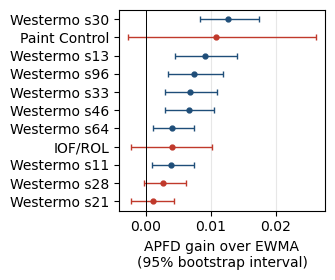

saved /Users/anis/My Research/Software Testing/ML Test Prio/outputs/fig_forest_m1.png


In [62]:
importlib.reload(m1_real)
m1_real.plot_forest(M1["table"], os.path.join(OUT_DIR, "fig_forest_m1.png"))

In [63]:
import importlib, m1_harness, m1_real, m6_cost
for m in (m1_harness, m1_real, m6_cost): importlib.reload(m)
M6 = m6_cost.run_m6(CT, PROJS, build_pool, prep_test, fit_rank,
                    STAT_BASE, DEFAULT, SEED, out_dir=OUT_DIR)

paintcontrol   done in  16.3 s  (kappa = 0.5)
iofrol         done in  17.1 s  (kappa = 0.5)
westermo_s11   done in  15.6 s  (kappa = 0.5)
westermo_s13   done in  33.7 s  (kappa = 2.0)
westermo_s21   done in  23.7 s  (kappa = 0.5)
westermo_s28   done in  25.9 s  (kappa = 0.5)
westermo_s30   done in  45.3 s  (kappa = 0.5)
westermo_s33   done in  40.8 s  (kappa = 0.5)
westermo_s46   done in  44.9 s  (kappa = 0.5)
westermo_s64   done in  43.1 s  (kappa = 0.5)
westermo_s96   done in  22.9 s  (kappa = 0.5)

Checks
  prefix invariance of p_hat / d_hat inputs : PASS
  EWMA APFD with tie seed 0 (must be 0.7522): 0.7522
  ranker calibration slope > 0 everywhere   : True
  kappa chosen on training projects         : {'paintcontrol': 0.5, 'iofrol': 0.5, 'westermo_s11': 0.5, 'westermo_s13': 2.0, 'westermo_s21': 0.5, 'westermo_s28': 0.5, 'westermo_s30': 0.5, 'westermo_s33': 0.5, 'westermo_s46': 0.5, 'westermo_s64': 0.5, 'westermo_s96': 0.5}

Table A: project means (20 tie-breaks x 5 model seeds)
   

In [64]:
import importlib, m1_harness, m1_real, m6_cost, m5_ties
for m in (m1_harness, m1_real, m6_cost, m5_ties): importlib.reload(m)
M5 = m5_ties.run_m5(CT, PROJS, build_pool, prep_test, fit_rank,
                    STAT_BASE, DEFAULT, SEED, out_dir=OUT_DIR)

paintcontrol   done in  13.4 s
iofrol         done in  13.6 s
westermo_s11   done in  12.2 s
westermo_s13   done in  33.0 s
westermo_s21   done in  24.2 s
westermo_s28   done in  26.3 s
westermo_s30   done in  48.7 s
westermo_s33   done in  44.1 s
westermo_s46   done in  48.8 s
westermo_s64   done in  47.3 s
westermo_s96   done in  22.7 s

Checks
  EWMA APFD with tie seed 0 (must be 0.7522): 0.7522
  Ranker APFD (must match M1, 0.7585)        : 0.7585

Table A: ties under EWMA and how much room they leave (APFD; 11 systems)
               tests_tied_%  tests_at_zero_%  failing_tied_%  tie_headroom  ranker_gain  ranker_in_ties_gain  pass_streak_gain
Paint Control       30.5659           1.0894         21.4597        0.0006       0.0108               0.0000            0.0000
IOF/ROL             59.9456          23.4281         55.4073        0.0378       0.0041               0.0055            0.0030
Westermo s11        33.5018          18.2980         15.5633        0.0059       0.0039  

In [65]:
import importlib, m3_transfer
importlib.reload(m3_transfer)
M3 = m3_transfer.run_m3(CT, PROJS, build_pool, prep_test, fit_rank,
                        STAT_BASE, DEFAULT, SEED, out_dir=OUT_DIR)

paintcontrol   done in   29.1 s
iofrol         done in   27.0 s
westermo_s11   done in   28.0 s
westermo_s13   done in   45.8 s
westermo_s21   done in   35.9 s
westermo_s28   done in   29.1 s
westermo_s30   done in   36.0 s
westermo_s33   done in   33.8 s
westermo_s46   done in   35.3 s
westermo_s64   done in   34.5 s
westermo_s96   done in   28.8 s
all protocols done in 6.1 min

Checks
  rebuilt LightGBM model equals the notebook's fit_rank: max |diff| = 0.00e+00

Table A: Westermo targets, APFD gain over EWMA by training set
              LOPO-A (8W+2A)  same family (8W)  2W median  2W min  2W max  2W pairs >0 (%)  1W median  LOPO-B (2A)
system                                                                                                            
Westermo s11          0.0040            0.0029     0.0009 -0.0083  0.0033          64.2857    -0.0058      -0.0118
Westermo s13          0.0089            0.0076     0.0023 -0.0151  0.0096          57.1429    -0.0039      -0.1141
Westerm

In [67]:
def verdict_counts(path):
    with open(path, "r", errors="ignore") as fh:
        head = fh.readline()
    sep = ";" if head.count(";") > head.count(",") else ("\t" if head.count("\t") > head.count(",") else ",")
    df = pd.read_csv(path, sep=sep, usecols=lambda c: c.strip() == "Verdict")
    return df.iloc[:, 0].value_counts().sort_index().to_dict()

for t in PROJS:
    if t.startswith("westermo"):
        print(t, verdict_counts(PROJECT_FILES[t]))

westermo_s11 {0: 38801, 1: 3175}
westermo_s13 {0: 78466, 1: 3392}
westermo_s21 {0: 62482, 1: 3314}
westermo_s28 {0: 64344, 1: 4561}
westermo_s30 {0: 177285, 1: 7530}
westermo_s33 {0: 160056, 1: 7204}
westermo_s46 {0: 180132, 1: 7299}
westermo_s64 {0: 155822, 1: 10156}
westermo_s96 {0: 67294, 1: 5505}


In [68]:
rows = []
for t in PROJS:
    c = CT[t]
    ft = pd.to_datetime(c["first_time"])
    g = c.assign(ft=ft).groupby("Cycle")["ft"].agg(["min", "max"])
    rows.append(dict(project=t, first=ft.min(), last=ft.max(), cycles=len(g),
                     missing_time_pct=round(100 * ft.isna().mean(), 2),
                     cycles_in_time_order=bool(g["min"].is_monotonic_increasing),
                     median_cycle_hours=round((g["max"] - g["min"]).dt.total_seconds().median() / 3600, 2)))
print(pd.DataFrame(rows).to_string(index=False))

     project               first                last  cycles  missing_time_pct  cycles_in_time_order  median_cycle_hours
paintcontrol 2016-01-12 09:17:00 2016-12-20 20:45:00     352               0.0                  True               23.88
      iofrol 2015-02-13 16:13:00 2016-10-25 16:20:00     320               0.0                  True                1.23
westermo_s11 1970-06-21 09:45:21 1970-12-22 11:51:08     326               0.0                  True                1.19
westermo_s13 1970-02-01 23:33:23 1971-08-02 08:02:41    2281               0.0                 False                0.17
westermo_s21 1970-08-13 23:30:16 1971-08-02 13:43:17    1105               0.0                 False                0.19
westermo_s28 1970-06-17 23:33:50 1971-08-02 06:50:46    1165               0.0                  True                0.31
westermo_s30 1970-02-03 01:48:21 1971-08-02 10:47:18    2295               0.0                 False                0.21
westermo_s33 1970-02-03 01:50:31

In [69]:
from scipy.stats import spearmanr
rows = []
for t in PROJS:
    c = CT[t]
    g = (c.assign(ft=pd.to_datetime(c["first_time"]))
           .groupby("Cycle")["ft"].agg(["min", "max"]).sort_index())
    start, end = g["min"], g["max"]
    # latest end time among all LOWER-numbered cycles, compared with this cycle's start
    prev_end = end.cummax().shift(1)
    lag_h = ((prev_end - start).dt.total_seconds() / 3600).fillna(0)
    rows.append(dict(project=t, cycles=len(g),
                     starts_before_previous_pct=round(100 * (start.diff().dt.total_seconds() < 0).mean(), 1),
                     uses_unfinished_cycle_pct=round(100 * (lag_h > 0).mean(), 1),
                     lag_median_h=round(lag_h[lag_h > 0].median(), 2) if (lag_h > 0).any() else 0,
                     lag_p95_h=round(lag_h[lag_h > 0].quantile(0.95), 2) if (lag_h > 0).any() else 0,
                     lag_max_h=round(lag_h.max(), 1),
                     cycles_lag_over_24h=int((lag_h > 24).sum()),
                     spearman_cycle_vs_time=round(spearmanr(start.index, start.values.astype("int64")).correlation, 4)))
print(pd.DataFrame(rows).to_string(index=False))

     project  cycles  starts_before_previous_pct  uses_unfinished_cycle_pct  lag_median_h  lag_p95_h  lag_max_h  cycles_lag_over_24h  spearman_cycle_vs_time
paintcontrol     352                         0.0                        0.0          0.00       0.00        0.0                    0                  1.0000
      iofrol     320                         0.0                        0.0          0.00       0.00        0.0                    0                  1.0000
westermo_s11     326                         0.0                        0.9         39.71      40.19       40.2                    2                  1.0000
westermo_s13    2281                         0.0                        0.2          3.77       8.35        9.2                    0                  1.0000
westermo_s21    1105                         0.3                        0.8        213.15     218.56      221.7                    5                  0.9999
westermo_s28    1165                         0.0          

In [70]:
import importlib, m3_transfer, m4_time
importlib.reload(m3_transfer); importlib.reload(m4_time)
M4 = m4_time.run_m4(CT, PROJS, build_pool, prep_test, fit_rank,
                    STAT_BASE, DEFAULT, SEED, out_dir=OUT_DIR)

paintcontrol   done in   69.0 s
iofrol         done in   67.7 s
westermo_s11   done in   41.4 s
westermo_s13   done in  113.9 s
westermo_s21   done in   81.7 s
westermo_s28   done in   89.9 s
westermo_s30   done in  142.8 s
westermo_s33   done in  115.5 s
westermo_s46   done in  114.6 s
westermo_s64   done in  107.8 s
westermo_s96   done in   50.9 s
all done in 16.6 min

Checks
  pool builder reproduces the notebook's build_pool : True
  same-organization training cycles that ended after their block started: 0 (must be 0)

Table: APFD gain over EWMA, untimed vs time-aligned LOPO-A (3 seeds; strict and 14-day variants with 1 seed)
               eval cycles  untimed LOPO-A  time-aligned (30d)  difference  same org only (30d)  time-aligned (14d)  cycles ranked by model (%)  same-org-only ranked (%)  mean training cycles  untimed, without overlapping cycles  overlapping cycles excluded  check violations
system                                                                                

In [71]:
importlib.reload(m4_time)
S4 = m4_time.summarize_m4(M4, PROJS, prep_test, out_dir=OUT_DIR)

Time-aligned LOPO-A, practical size (3 seeds; exact expected APFD over tie-breaks)
               cycles  tests_median    EWMA  ranker (time-aligned)    gain  gain_lo  gain_hi  positions_earlier     A12       W       T       L  untimed gain  p_holm
Westermo s30   1112.0           9.0  0.7825                 0.7931  0.0106   0.0063   0.0155             1.1109  0.5112   258.0   657.0   197.0        0.0127  0.0031
Westermo s96    555.0          11.0  0.7358                 0.7424  0.0066   0.0027   0.0111             1.0206  0.5118   122.0   348.0    85.0        0.0071  0.0203
Paint Control   219.0          78.0  0.7823                 0.7887  0.0065  -0.0082   0.0221             0.4050  0.5005    56.0   101.0    62.0        0.0107  1.0000
Westermo s13    889.0          77.0  0.7593                 0.7657  0.0064   0.0015   0.0115             0.3441  0.5093   229.0   461.0   199.0        0.0089  0.6023
Westermo s33   1111.0          10.0  0.7902                 0.7958  0.0055   0.0014   0

In [72]:
import importlib, m1_learners
importlib.reload(m1_learners)
PL = m1_learners.run_published(CT, PROJS, build_pool, prep_test, fit_rank,
                               STAT_BASE, DEFAULT, SEED, out_dir=OUT_DIR)

paintcontrol   done in   15.2 s  (tuned k=1.0, H=30)
iofrol         done in   23.9 s  (tuned k=0.2, H=30)
westermo_s11   done in   14.0 s  (tuned k=0.2, H=5)
westermo_s13   done in   53.7 s  (tuned k=1.0, H=30)
westermo_s21   done in   32.5 s  (tuned k=0.5, H=30)
westermo_s28   done in   38.5 s  (tuned k=0.5, H=5)
westermo_s30   done in   87.6 s  (tuned k=1.0, H=30)
westermo_s33   done in   83.9 s  (tuned k=0.5, H=30)
westermo_s46   done in   88.7 s  (tuned k=0.2, H=15)
westermo_s64   done in   81.7 s  (tuned k=1.0, H=15)
westermo_s96   done in   36.1 s  (tuned k=0.8, H=15)
all done in 9.3 min

Table A: published learners vs EWMA (mean APFD over 11 systems; Holm-corrected per-cycle Wilcoxon)
                                                      APFD  gain vs EWMA  systems > EWMA  sig. better  sig. worse  worst system gain  p over systems
method                                                                                                                                              
R